# **Modelado Predictivo del Nivel del Río en la Estación Hidrológica "El Banco - Aut" Mediante Aprendizaje Automático Supervisado**

# **1. Descripción del problema e inspección del conjunto de datos**
# **1.1. Descripción del problema**

El río Magdalena es el principal río de Colombia y su nivel cambia a lo largo del año según las temporadas de lluvia. En el municipio de El Banco (Magdalena), cuando el nivel sube demasiado, el río se desborda e inunda barrios y corregimientos. Por ejemplo, en noviembre de 2021 se declaró alerta roja y luego calamidad pública en El Banco por el desbordamiento del río, con un nivel cercano a 8.7 m (La FM, 2021), y en mayo de 2022 al menos 12 barrios de la parte baja del municipio se inundaron cuando el nivel superó los 9 m (Radio Nacional de Colombia, 2022). Poder anticipar el nivel del río con algunos días de ventaja ayudaría a las autoridades y a la población a prepararse para estos eventos.

Para este trabajo se usa el conjunto de datos "Nivel Instantáneo del Río", publicado por el Instituto de Hidrología, Meteorología y Estudios Ambientales - IDEAM, Bogotá D.C. (https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Nivel-Instant-neo-del-Rio/bdmn-sqnh/about_data). Contiene las mediciones de la estación automática "EL BANCO - AUT" (código 25027020), que mide el nivel del río Magdalena en ese municipio. El conjunto tiene 315876 registros, desde el 1 de enero de 2005 hasta el 19 de octubre de 2026, y 12 variables:

| Variable | Descripción |
|---|---|
| CodigoEstacion | Código de la estación de medición (25027020) |
| CodigoSensor | Código del sensor que toma la medición |
| FechaObservacion | Fecha y hora de la medición |
| ValorObservado | Nivel del río medido, en metros |
| NombreEstacion | Nombre de la estación ("EL BANCO - AUT") |
| Departamento | Departamento donde está la estación (Magdalena) |
| Municipio | Municipio donde está la estación (El Banco) |
| ZonaHidrografica | Zona hidrográfica a la que pertenece la estación |
| Latitud | Latitud de la estación |
| Longitud | Longitud de la estación |
| DescripcionSensor | Tipo de medición (nivel instantáneo) |
| UnidadMedida | Unidad de la medición (metros) |

Como todos los registros son de la misma estación, las variables de ubicación, código, sensor y unidad tienen el mismo valor en todas las filas y no aportan información para predecir. Por eso solo se usan *FechaObservacion* y *ValorObservado*, que forman una serie de tiempo: el nivel del río medido a lo largo de los años.

**Objetivo:** construir modelos de aprendizaje supervisado que predigan el nivel promedio del río en la estación El Banco para la semana siguiente, a partir del nivel de las semanas anteriores y de la época del año. Como el valor a predecir es un número (el nivel en metros), se trata de un problema de **regresión**, y los modelos se evaluarán con métricas como el error cuadrático medio (MSE), el error absoluto medio (MAE), el coeficiente de determinación (R²) y el error porcentual absoluto medio (MAPE).

**Referencias**
- La FM (7 de noviembre de 2021). *Por desbordamiento del río Magdalena declaran alerta roja en el municipio El Banco*. https://www.lafm.com.co/colombia/por-desbordamiento-del-rio-magdalena-declaran-alerta-roja-en-el-municipio-el-banco
- Radio Nacional de Colombia (4 de mayo de 2022). *Desbordamiento del río Magdalena inundó barrios de El Banco*. https://radionacional.co/regiones/caribe/desbordamiento-rio-magdalena-inundo-barrios-de-el-banco
- El Heraldo (21 de noviembre de 2020). *Alerta roja por aumento del nivel del Magdalena*. https://www.elheraldo.co/atlantico/2020/11/21/alerta-roja-por-aumento-del-nivel-del-magdalena-774870/

# **1.2. Importación de librerías**
Se utilizan librerías como pandas y seaborn para la inspección y exploración de los datos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error)

# **1.3. Carga del dataset**
Se toman únicamente las dos variables de interés para nuestro análisis.

In [2]:
columnas_deseadas = ["FechaObservacion", "ValorObservado"]
df = pd.read_csv("Nivel_Instantáneo_del_Rio_20261020.csv", usecols=columnas_deseadas)

df.info()
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 315876 entries, 0 to 315875
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   FechaObservacion  315876 non-null  str  
 1   ValorObservado    315876 non-null  str  
dtypes: str(2)
memory usage: 4.8 MB


,FechaObservacion,ValorObservado
0,2011 Aug 15 11:00:00 AM,"6,73"
1,2005 Nov 15 02:00:00 PM,"6,15"
2,2011 May 10 05:00:00 AM,"9,43"
3,2009 Apr 29 07:00:00 AM,"7,25"
4,2016 Sep 17 07:00:00 PM,"6,12"


Las variables *FechaObservacion* y *ValorObservado* son de tipo object, se procede a hacer el cambio a tipo datetime y float respectivamente.

In [3]:
df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], errors="coerce")

df["ValorObservado"] = df["ValorObservado"].astype(str).str.replace(",", ".", regex=False)
df["ValorObservado"] = pd.to_numeric(df["ValorObservado"], errors="coerce")

df.info()
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 315876 entries, 0 to 315875
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   FechaObservacion  315876 non-null  datetime64[us]
 1   ValorObservado    315876 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 4.8 MB


,FechaObservacion,ValorObservado
0,2011-08-15 11:00:00,6.73
1,2005-11-15 14:00:00,6.15
2,2011-05-10 05:00:00,9.43
3,2009-04-29 07:00:00,7.25
4,2016-09-17 19:00:00,6.12


Se ordenan cronológicamente los registros.

In [4]:
df = df.sort_values(by="FechaObservacion", ascending=True).reset_index(drop=True)

display(df.head())
display(df.tail())

,FechaObservacion,ValorObservado
0,2005-01-01 17:00:00,8.65
1,2005-01-01 18:00:00,8.65
2,2005-01-01 19:00:00,8.66
3,2005-01-01 20:00:00,8.69
4,2005-01-01 21:00:00,8.67


,FechaObservacion,ValorObservado
315871,2026-10-19 19:00:00,5.05
315872,2026-10-19 20:00:00,5.06
315873,2026-10-19 21:00:00,5.06
315874,2026-10-19 22:00:00,5.08
315875,2026-10-19 23:00:00,5.09


# **1.4. Inspección inicial**
Se revisan valores faltantes, fechas duplicadas, posibles registros duplicados y valores
numéricos atípicos o imposibles.

In [5]:
print("\nResumen de valores faltantes:")
print(df.isna().sum())
df_fechas_duplicadas = df[df["FechaObservacion"].duplicated()].copy()
print("\nFechas duplicadas:", df["FechaObservacion"].duplicated().sum())
display(df_fechas_duplicadas.head())
print("\nRegistros duplicados:", df.duplicated().sum())

print("\nResumen de variable 'ValorObservado':")
display(df.select_dtypes(include="number").describe().T)

# Calcular Q1, Q3 e IQR
Q1 = df["ValorObservado"].quantile(0.25)
Q3 = df["ValorObservado"].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites superior e inferior
limite_inferior = Q1 - (1.5 * IQR)
limite_superior = Q3 + (1.5 * IQR)

# Filtrar los valores atípicos
outliers = df[(df["ValorObservado"] < limite_inferior) | (df["ValorObservado"] > limite_superior)]

print(f"\nCantidad de valores atípicos encontrados: {len(outliers)}")
display(outliers.head())


Resumen de valores faltantes:
FechaObservacion    0
ValorObservado      0
dtype: int64

Fechas duplicadas: 18054


,FechaObservacion,ValorObservado
102491,2019-08-28 00:00:00,6.39
102492,2019-08-28 00:00:00,6.39
102494,2019-08-28 01:00:00,6.39
102495,2019-08-28 01:00:00,6.39
102497,2019-08-28 02:00:00,6.39



Registros duplicados: 18054

Resumen de variable 'ValorObservado':


,count,mean,std,min,25%,50%,75%,max
ValorObservado,315876.0,6.538216,1.397943,0.0,5.77,6.47,7.29,172.42



Cantidad de valores atípicos encontrados: 926


,FechaObservacion,ValorObservado
2572,2005-04-22 17:00:00,20.49
2573,2005-04-22 19:00:00,167.67
4683,2005-07-22 03:00:00,172.42
18578,2007-02-22 13:00:00,2.40
18579,2007-02-22 14:00:00,2.40


Se puede observar que no hay valores faltantes, pero sí 18054 registros duplicados. Como el número de fechas repetidas es igual al número de filas repetidas, cada fecha repetida trae exactamente el mismo valor; es decir, son copias exactas que envió el sensor y se pueden eliminar sin perder información.

Con el método del rango intercuartílico (IQR) se encontraron 926 valores atípicos, tanto por debajo del límite inferior (por ejemplo 2.40 m) como por encima del límite superior (por ejemplo 167.67 m y 172.42 m).

Antes de tratar los atípicos se eliminan los duplicados, dejando un único registro.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)

#Verificamos duplicados restantes
print("\nFechas duplicadas restantes:", df["FechaObservacion"].duplicated().sum())
print("Registros duplicados restantes:", df.duplicated().sum())
print(f"\nTotal de registros en el dataset: {len(df)}")



Fechas duplicadas restantes: 0
Registros duplicados restantes: 0

Total de registros en el dataset: 297822


Los límites del IQR se vuelven a calcular sobre los datos sin duplicados. Los registros duplicados contaban dos veces algunos valores, y eso desplaza los cuartiles. Después se revisan los valores más bajos y más altos de la serie para ubicar los límites físicos.

Q1 = 5.74 m | Q3 = 7.31 m | IQR = 1.57 m
Límites del IQR: [3.39 m , 9.66 m]
Registros fuera de los límites: 720
   por debajo del límite inferior: 224
   por encima del límite superior: 496

15 valores únicos más bajos: [0.   0.14 0.15 0.16 0.17 0.18 0.19 0.2  0.21 0.3  2.4  2.63 3.74 3.82
 3.83]
15 valores únicos más altos: [ 10.59  10.6   10.61  10.62  10.63  10.64  15.36  17.92  20.49  28.16
  29.78  52.28  87.22 167.67 172.42]


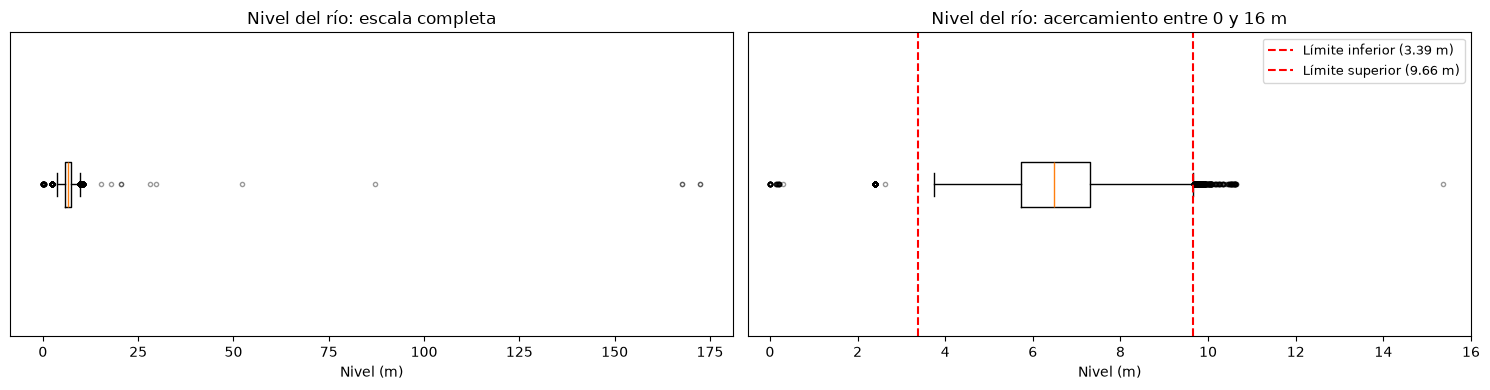

In [7]:
# Se trabaja sobre el DataFrame ya SIN duplicados y ordenado en el tiempo
df = df.sort_values("FechaObservacion").reset_index(drop=True)

# Se recalculan los límites del IQR sobre los datos sin duplicados
Q1 = df["ValorObservado"].quantile(0.25)
Q3 = df["ValorObservado"].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df["fuera_iqr"] = (df["ValorObservado"] < limite_inferior) | (df["ValorObservado"] > limite_superior)

print(f"Q1 = {Q1:.2f} m | Q3 = {Q3:.2f} m | IQR = {IQR:.2f} m")
print(f"Límites del IQR: [{limite_inferior:.2f} m , {limite_superior:.2f} m]")
print(f"Registros fuera de los límites: {df['fuera_iqr'].sum()}")
print(f"   por debajo del límite inferior: {(df['ValorObservado'] < limite_inferior).sum()}")
print(f"   por encima del límite superior: {(df['ValorObservado'] > limite_superior).sum()}")

# Valores únicos más altos y más bajos: sirven para ver dónde terminan los valores posibles
valores_unicos = np.sort(df["ValorObservado"].unique())
print("\n15 valores únicos más bajos:", valores_unicos[:15])
print("15 valores únicos más altos:", valores_unicos[-15:])

# Diagrama de caja
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].boxplot(df["ValorObservado"], orientation="horizontal", whis=1.5,
                flierprops=dict(marker="o", markersize=3, alpha=0.4))
axes[0].set_title("Nivel del río: escala completa")
axes[0].set_xlabel("Nivel (m)")
axes[0].set_yticks([])

axes[1].boxplot(df["ValorObservado"], orientation="horizontal", whis=1.5,
                flierprops=dict(marker="o", markersize=3, alpha=0.4))
axes[1].axvline(limite_inferior, color="red", linestyle="--", label=f"Límite inferior ({limite_inferior:.2f} m)")
axes[1].axvline(limite_superior, color="red", linestyle="--", label=f"Límite superior ({limite_superior:.2f} m)")
axes[1].set_xlim(-0.5, 16)
axes[1].set_title("Nivel del río: acercamiento entre 0 y 16 m")
axes[1].set_xlabel("Nivel (m)")
axes[1].set_yticks([])
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

Los límites del IQR quedaron en 3.39 m y 9.66 m, con 224 registros por debajo y 496 por encima.

En la lista de valores más altos se ve que los niveles aumentan de forma continua hasta 10.64 m y luego saltan a 15.36 m, sin valores intermedios. Ese salto de casi 5 m marca dónde terminan los valores posibles, por lo que se toma 15 m como límite físico máximo.

En la lista de valores más bajos ocurre algo parecido: hay valores entre 0 y 0.3 m y luego el siguiente es 2.4 m. Un nivel de pocos centímetros no es posible en este punto del río, por lo que se toma 1 m como límite físico mínimo.

El diagrama de caja muestra visualmente el resultado del IQR. La caja representa el 50 % central de los datos (entre Q1 = 5.74 m y Q3 = 7.31 m), la línea dentro de ella es la mediana, los bigotes se extienden hasta el último valor que todavía está dentro de los límites del IQR (marcados con líneas rojas), y los puntos fuera de ellos son los registros considerados atípicos. El bigote inferior no llega hasta la línea del límite inferior (3.39 m) porque no hay ningún registro entre ese límite y 3.74 m; el bigote termina en el valor real más bajo dentro del rango. En la escala completa, la caja queda comprimida contra el extremo izquierdo porque algunos valores llegan a más de 170 m, lo que ya evidencia la presencia de errores. En el acercamiento se observa que hay atípicos en ambos lados de la caja: por debajo, con valores cercanos a 0 m y alrededor de 2.4 m, y por encima, entre unos 9.7 m y 10.6 m. El diagrama no permite saber cuáles de estos puntos son errores y cuáles son niveles reales del río, y por eso se analizan más adelante.

## **1.4.1. Clasificación de los valores atípicos**

El método IQR solo indica qué tan lejos está un dato del centro de la distribución, pero no indica si ese dato es un error. En una serie de nivel de río esto importa, porque los valores más altos pueden ser crecientes reales del río y los más bajos pueden ser temporadas secas. Si se eliminan, el modelo nunca vería esos eventos, y son justamente los más importantes de predecir. Además, el IQR no puede detectar errores cuyo valor parece normal, como un sensor que repite el mismo dato durante días.

Por esta razón, en vez de eliminar todo lo que el IQR marca, cada registro se clasifica con reglas basadas en el comportamiento físico del río:

| Categoría | Regla | Tratamiento |
|---|---|---|
| Error: valor imposible | Nivel < 1 m o > 15 m | Se elimina |
| Error: sensor pegado | El mismo valor exacto se repite 24 horas o más | Se elimina |
| Error: salto brusco | El valor se aleja más de 0.3 m de la mediana de las 24 horas a su alrededor, ya sea un punto suelto o un bloque de varias horas | Se elimina |
| Extremo real | Está fuera de los límites del IQR pero no cumple ninguna de las reglas anteriores | Se conserva |


### **Regla 1: valores físicamente imposibles**
Un nivel por debajo de 1 m significa que el sensor no registró bien la medición, ya que el río no baja a ese nivel en este punto. Los valores por encima del límite físico máximo corresponden a errores de transmisión.

In [8]:
LIMITE_FISICO_MIN = 1.0   
LIMITE_FISICO_MAX = 15.0  

df["imposible"] = (df["ValorObservado"] < LIMITE_FISICO_MIN) | (df["ValorObservado"] > LIMITE_FISICO_MAX)

print(f"Registros con valores imposibles: {df['imposible'].sum()}")
imposibles = df.loc[df["imposible"], ["FechaObservacion", "ValorObservado"]]
display(imposibles)

Registros con valores imposibles: 48


,FechaObservacion,ValorObservado
2572,2005-04-22 17:00:00,20.49
2573,2005-04-22 19:00:00,167.67
4683,2005-07-22 03:00:00,172.42
19945,2007-04-22 17:00:00,20.49
19946,2007-04-22 19:00:00,167.67
22056,2007-07-22 03:00:00,172.42
45446,2010-03-25 11:00:00,0.00
61081,2012-01-08 08:00:00,15.36
62265,2012-02-27 05:00:00,87.22
62266,2012-02-27 06:00:00,28.16


Se encontraron 48 registros imposibles, que se pueden agrupar en tres casos:

- **Valores demasiado altos (12 registros):** entre 15.36 m y 172.42 m. Los valores de 2005 (20.49 m y 167.67 m el 22 de abril, y 172.42 m el 22 de julio) se repiten exactamente iguales, en el mismo día y hora, en 2007, lo que indica un error en el registro de los datos y no un comportamiento del río.
- **Valores cercanos a cero (17 registros):** entre el 18 y el 19 de septiembre de 2018 el sensor marcó entre 0.14 m y 0.30 m durante unas 17 horas seguidas, lo que corresponde a una falla continua del sensor.
- **Valores en 0 m (19 registros):** la mayoría ocurre en 2024 y 2025, siempre entre las 03:40 y las 04:00 de la madrugada. Que se repitan a la misma hora sugiere un reinicio o mantenimiento del equipo y no un evento real.

### **Regla 2: sensor pegado**
El sensor mide con precisión de centímetro, así que el nivel de un río real cambia aunque sea un poco a lo largo de un día. Cuando el mismo valor exacto se repite durante muchas horas seguidas, lo más probable es que el sensor dejó de medir y siguió enviando el último dato.

Para encontrar estos casos se divide la serie en tramos donde el valor no cambia. Un tramo nuevo empieza cuando el valor cambia o cuando hay más de 3 horas sin datos. Se usan 3 horas porque el sensor mide como máximo cada hora, así que 3 horas sin datos significa que se perdieron al menos dos mediciones seguidas. Si el valor es igual antes y después de un hueco así, no hay forma de saber qué pasó en medio, y unir esos datos haría parecer que el sensor estuvo pegado cuando en realidad no hubo datos.

In [9]:
HORAS_PEGADO = 24

# Empieza un "tramo" nuevo cada vez que el valor cambia o cuando hay más de
# 3 horas sin datos (así un hueco largo no une dos tramos distintos)
cambia_valor = df["ValorObservado"].ne(df["ValorObservado"].shift())
salto_tiempo = df["FechaObservacion"].diff() > pd.Timedelta(hours=3)
df["id_tramo"] = (cambia_valor | salto_tiempo).cumsum()

# Duración de cada tramo con valor constante
tramos = df.groupby("id_tramo").agg(
    valor=("ValorObservado", "first"),
    inicio=("FechaObservacion", "min"),
    fin=("FechaObservacion", "max"),
    registros=("ValorObservado", "size"),
)
tramos["duracion_h"] = (tramos["fin"] - tramos["inicio"]).dt.total_seconds() / 3600

print("Tramos en los que el valor no cambió durante:")
for h in [3, 6, 12, 24, 48]:
    print(f"   {h:>2} horas o más: {(tramos['duracion_h'] >= h).sum()} tramos")

tramos_pegados = tramos[tramos["duracion_h"] >= HORAS_PEGADO]
df["pegado"] = df["id_tramo"].isin(tramos_pegados.index)

print(f"\nTramos con sensor pegado (>= {HORAS_PEGADO} h): {len(tramos_pegados)}")
print(f"Registros afectados: {df['pegado'].sum()}")
display(tramos_pegados.sort_values("duracion_h", ascending=False))

# Valores de falla conocidos: si un valor ya se identificó como sensor pegado
# en un tramo largo y además está fuera de los límites del IQR, cualquier otra
# aparición de ese valor fuera de los límites corresponde a la misma falla
valores_falla = tramos_pegados.loc[
    (tramos_pegados["valor"] < limite_inferior) | (tramos_pegados["valor"] > limite_superior), "valor"
].unique()
marcar = df["ValorObservado"].isin(valores_falla) & df["fuera_iqr"] & ~df["pegado"]
df["pegado"] = df["pegado"] | marcar

print(f"\nValores de falla conocidos fuera del IQR: {valores_falla}")
print(f"Registros adicionales marcados por repetir un valor de falla: {marcar.sum()}")
print(f"Total de registros con sensor pegado: {df['pegado'].sum()}")

Tramos en los que el valor no cambió durante:
    3 horas o más: 4728 tramos
    6 horas o más: 955 tramos
   12 horas o más: 180 tramos
   24 horas o más: 56 tramos
   48 horas o más: 35 tramos

Tramos con sensor pegado (>= 24 h): 56
Registros afectados: 14034


,valor,inicio,fin,registros,duracion_h
id_tramo,,,,,
51392,6.39,2018-12-20 10:00:00,2019-04-02 01:00:00,2464,2463.0
52454,6.39,2019-07-08 18:00:00,2019-09-14 23:00:00,1637,1637.0
42874,4.28,2015-12-26 20:00:00,2016-02-29 08:00:00,1549,1548.0
50373,6.55,2018-07-22 00:00:00,2018-09-17 21:00:00,1390,1389.0
49199,4.27,2018-01-27 23:00:00,2018-03-11 12:00:00,1016,1021.0
53608,5.15,2020-02-25 01:00:00,2020-03-16 21:00:00,501,500.0
53605,5.15,2020-01-25 18:00:00,2020-02-11 20:00:00,411,410.0
49200,4.27,2018-03-11 16:00:00,2018-03-28 13:00:00,403,405.0
52455,6.39,2019-09-18 00:00:00,2019-09-30 11:00:00,300,299.0



Valores de falla conocidos fuera del IQR: [2.4]
Registros adicionales marcados por repetir un valor de falla: 35
Total de registros con sensor pegado: 14069


La tabla muestra que es normal que el valor se repita algunas horas (955 tramos de 6 h o más), ya que el nivel del río puede mantenerse estable por periodos cortos. Sin embargo, que el mismo valor exacto se mantenga 24 horas o más es poco común (56 tramos), por lo que se toma 24 horas como umbral. Un día completo es el periodo en el que el nivel del río debería cambiar al menos un centímetro, incluso en temporada seca. Se consideró usar 48 horas, pero solo cambiaría la clasificación de 21 tramos cortos (56 − 35), mientras que la mayoría de los registros afectados pertenecen a tramos de semanas o meses que quedan marcados con cualquiera de los dos umbrales.

Se encontraron 56 tramos con el sensor pegado, que suman 14034 registros. Algunos duran semanas o meses: el más largo va del 20 de diciembre de 2018 al 2 de abril de 2019, con un valor fijo de 6.39 m durante 2463 horas (unos 103 días). También hay tramos largos de 6.39 m entre julio y septiembre de 2019, de 4.28 m entre diciembre de 2015 y febrero de 2016, y de 6.55 m entre julio y septiembre de 2018. Ningún río mantiene el mismo nivel, al centímetro, durante meses.

La mayoría de estos valores (6.39 m, 6.55 m, 5.15 m, 4.28 m) están dentro de los límites del IQR, por lo que ese método no podía detectarlos: el valor parece normal y lo que lo delata es que no cambia en el tiempo. Además, el tramo de 6.39 m de 2019 coincide con el periodo en que aparecieron los registros duplicados, lo que sugiere una falla general del equipo en esas fechas.

Al revisar los resultados de la clasificación se encontraron registros con un valor de 2.40 m el 22 y 23 de febrero de 2007 que no alcanzaban a sumar 24 horas seguidas, porque el sensor alternaba con otros valores erróneos. Sin embargo, 2.40 m es el mismo valor en el que el sensor quedó fijo durante 151 horas en febrero de 2009, y está por debajo del límite inferior del IQR. Por eso se agregó una condición: si un valor ya se identificó como sensor pegado en un tramo largo y además está fuera de los límites del IQR, cualquier otra aparición de ese valor fuera de esos límites se considera la misma falla. La condición de estar fuera del IQR evita marcar valores como 6.39 m o 4.28 m, que también aparecieron pegados pero que el río sí puede alcanzar en condiciones normales.

El único valor que cumplió esta condición fue 2.40 m, con 35 registros adicionales. Con ellos, el total de registros con sensor pegado es de 14069.

### **Regla 3: saltos bruscos**
Se espera que el nivel de un río tan grande como el Magdalena cambie de forma gradual, del orden de centímetros por hora. Por eso, si en algún registro el nivel subiera o bajara de golpe un metro o más y poco después volviera a su valor anterior, sería un comportamiento poco probable para el río y podría clasificarse como un error del sensor. Para comprobar esta suposición se calculó cuánto cambia el nivel entre dos mediciones separadas exactamente una hora, excluyendo los errores ya identificados en las reglas 1 y 2.

In [10]:
validos = df[~(df["imposible"] | df["pegado"])].copy()
validos["horas"] = validos["FechaObservacion"].diff().dt.total_seconds() / 3600
validos["cambio"] = validos["ValorObservado"].diff().abs()

# Solo pares de mediciones separadas exactamente 1 hora
cambio_horario = validos.loc[validos["horas"] == 1, "cambio"]
print("Cambio del nivel entre dos mediciones separadas 1 hora (m):")
print(cambio_horario.quantile([0.50, 0.90, 0.99, 0.999]).round(3).to_string())
print(f"\nCambios de más de 1 m en una hora: {(cambio_horario > 1).sum()} de {len(cambio_horario)}")

Cambio del nivel entre dos mediciones separadas 1 hora (m):
0.500    0.01
0.900    0.02
0.990    0.08
0.999    2.70

Cambios de más de 1 m en una hora: 367 de 100474


Se puede evidenciar que en la mitad de los casos el nivel cambió 1 cm o menos, en el 90 % menos de 2 cm y en el 99 % menos de 8 cm, lo que confirma que el río cambia de forma gradual. Sin embargo, el 0.1 % restante presenta cambios de hasta 2.70 m en una sola hora, y se encontraron 367 cambios de más de 1 m (0.37 % de los casos). El paso de 8 cm a varios metros entre los percentiles 99 y 99.9 muestra que estos cambios no son una variación mayor de lo normal, sino un comportamiento distinto, propio de errores del sensor, que se busca detectar con la siguiente regla.
Para detectarlos se calcula, para cada registro, la mediana de los valores de las 12 horas anteriores y las 12 horas posteriores (mediana móvil centrada de 24 horas). Las decisiones de este método son:

- **Mediana y no media:** la media se deja arrastrar por los mismos valores erróneos que se quieren detectar; la mediana no, mientras los datos correctos sean la mayoría de la ventana.
- **Ventana de 24 horas:** los bloques de saltos observados duran algunas horas, así que en una ventana de 24 horas los datos correctos siguen siendo mayoría y la mediana representa el nivel real. Una ventana más corta podría quedar dominada por un bloque de error. Una más larga dejaría de seguir los cambios reales del río, porque en varios días el nivel sí puede subir o bajar.
- **Ventana centrada:** se miran las horas antes y después del registro, porque un error se reconoce justamente porque el valor no encaja con lo que pasó antes ni con lo que pasó después.
- **Mínimo de 3 datos en la ventana:** con menos datos la mediana no es confiable, así que esos registros no se evalúan.
- **Sin los errores ya detectados:** los valores imposibles y los del sensor pegado se excluyen del cálculo de la mediana, porque si no, la referencia quedaría contaminada.

Percentiles de la desviación respecto a la mediana móvil de 24 h (m):
0.500    0.005
0.900    0.020
0.990    0.370
0.999    1.610

Registros que superarían cada umbral candidato:
   > 0.1 m: 3368
   > 0.2 m: 3012
   > 0.3 m: 2923
   > 0.5 m: 2707
   > 1.0 m: 1246


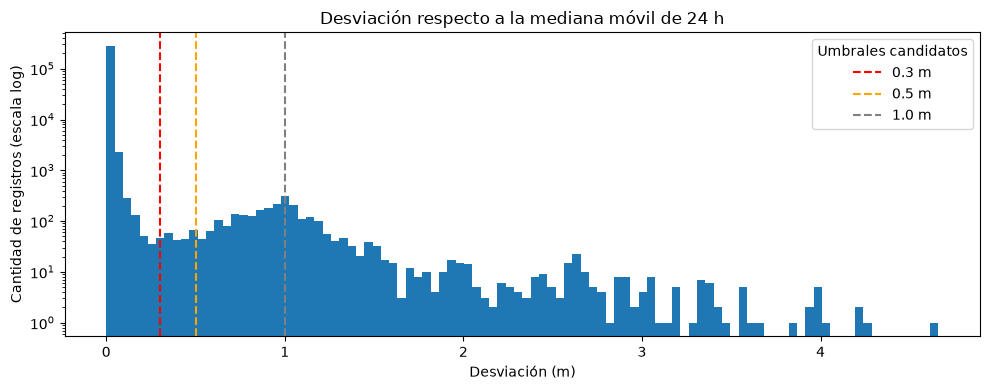


Registros por encima del límite superior del IQR, por mes:


,registros,desviacion_min,desviacion_max
FechaObservacion,,,
2020-12,35,0.000,0.075
2022-09,66,1.110,2.060
2022-10,336,0.710,1.710
2022-11,39,0.310,1.370
2022-12,6,0.570,1.450
2024-12,1,2.475,2.475
2025-05,1,1.850,1.850


In [11]:
VENTANA = "24h"

serie = df.set_index("FechaObservacion")["ValorObservado"]

# La mediana de referencia se calcula sin los errores ya identificados
ya_es_error = (df["imposible"] | df["pegado"]).to_numpy()
serie_referencia = serie.where(~ya_es_error)

# Mediana móvil centrada: para cada registro, la mediana de las 12 h antes y 12 h después
mediana_movil = serie_referencia.rolling(VENTANA, center=True, min_periods=3).median()
df["desviacion"] = (serie - mediana_movil).abs().to_numpy()
desv_validas = df.loc[~ya_es_error, "desviacion"].dropna()

print("Percentiles de la desviación respecto a la mediana móvil de 24 h (m):")
print(desv_validas.quantile([0.50, 0.90, 0.99, 0.999]).round(3).to_string())

print("\nRegistros que superarían cada umbral candidato:")
for u in [0.1, 0.2, 0.3, 0.5, 1.0]:
    print(f"   > {u} m: {(desv_validas > u).sum()}")

# Evidencia 1: histograma de la desviación con los umbrales candidatos
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(desv_validas, bins=100, color="#1f77b4")
ax.set_yscale("log")
for u, c in [(0.3, "red"), (0.5, "orange"), (1.0, "gray")]:
    ax.axvline(u, color=c, linestyle="--", label=f"{u} m")
ax.set_title("Desviación respecto a la mediana móvil de 24 h")
ax.set_xlabel("Desviación (m)")
ax.set_ylabel("Cantidad de registros (escala log)")
ax.legend(title="Umbrales candidatos")
plt.tight_layout()
plt.show()

# Evidencia 2: registros por encima del límite superior del IQR (que no son errores ya
# detectados), agrupados por mes, con su desviación mínima y máxima
altos = df[(df["ValorObservado"] > limite_superior) & ~ya_es_error]
resumen_altos = altos.groupby(altos["FechaObservacion"].dt.to_period("M"))["desviacion"].agg(
    registros="size", desviacion_min="min", desviacion_max="max"
).round(3)
print("\nRegistros por encima del límite superior del IQR, por mes:")
display(resumen_altos)

El histograma muestra dos grupos: la gran mayoría de los registros se aleja apenas unos centímetros de su mediana (el comportamiento normal del río), y un segundo grupo, mucho más pequeño, se concentra alrededor de 1 m de desviación (los saltos del sensor). Entre ambos hay un valle con muy pocos registros.

La tabla de registros por encima del límite superior del IQR permite comparar los dos casos directamente. En diciembre de 2020 los 35 registros se alejan como máximo 0.075 m de su mediana: el nivel subió y se mantuvo junto con la tendencia de su propio día, como en una creciente real. En cambio, en todos los demás meses (septiembre a diciembre de 2022, diciembre de 2024 y mayo de 2025) los valores se alejan como mínimo 0.31 m, y la mayoría más de 0.5 m: suben por encima de la tendencia de su día y luego vuelven a ella, como los saltos del sensor. Entre 0.075 m y 0.31 m no hay ningún registro, por lo que cualquier umbral dentro de ese rango separa ambos grupos.

El umbral se ajustó en varias pruebas. Con 1 m se dejaban pasar saltos de 0.8 a 0.95 m con la misma forma que los demás errores (por ejemplo, en septiembre de 2022), y con 0.5 m se dejaban pasar puntas de salto como las de noviembre de 2022. Por eso se tomó 0.3 m: queda dentro del rango vacío entre la creciente real (0.075 m) y el salto más pequeño encontrado (0.31 m), y coincide con la zona del valle del histograma.

In [12]:
UMBRAL_PICO = 0.3  # metros

df["pico"] = (df["desviacion"] > UMBRAL_PICO) & ~df["imposible"] & ~df["pegado"]

# ¿Los saltos vienen sueltos o en bloques?
rachas = (df["pico"] != df["pico"].shift()).cumsum()[df["pico"]].value_counts()
print(f"Registros clasificados como salto brusco (> {UMBRAL_PICO} m): {df['pico'].sum()}")
print(f"   saltos de un solo registro: {(rachas == 1).sum()}")
print(f"   bloques de 2 o más registros: {(rachas > 1).sum()}")
print("\nSaltos bruscos por año:")
print(df.loc[df["pico"], "FechaObservacion"].dt.year.value_counts().sort_index().to_string())

Registros clasificados como salto brusco (> 0.3 m): 2923
   saltos de un solo registro: 422
   bloques de 2 o más registros: 402

Saltos bruscos por año:
FechaObservacion
2005      90
2007      95
2008     346
2009       6
2010       2
2011       4
2012       1
2017      21
2018      17
2019      12
2020      49
2021       1
2022    1050
2023     174
2024     166
2025     879
2026      10


Se encontraron 2923 registros con saltos bruscos, agrupados en 422 saltos de un solo registro y 402 bloques de dos o más registros seguidos. Aunque la cantidad de saltos sueltos y de bloques es parecida, los bloques reúnen 2501 de los 2923 registros (cerca del 86 %). Esto muestra que el error más común del sensor no es un punto aislado, sino un desplazamiento temporal del nivel que dura varias horas. Los años con más casos son 2008, 2022 y 2025.

### **Clasificación final y comparación con el IQR**
Si un registro cumple varias reglas a la vez, se le asigna una sola categoría con este orden de prioridad: valor imposible, sensor pegado, salto brusco y, por último, extremo real. Los errores van antes que el extremo real porque un valor fuera del IQR que además cumple una regla de error no debe conservarse. Entre los errores, primero va el más evidente, para que el conteo de cada categoría refleje la causa principal.

In [13]:
# Clasificación final de cada registro (si cumple varias reglas, gana la de más abajo)
df["tipo_atipico"] = "normal"
df.loc[df["fuera_iqr"], "tipo_atipico"] = "extremo_real"
df.loc[df["pico"], "tipo_atipico"] = "error_salto_brusco"
df.loc[df["pegado"], "tipo_atipico"] = "error_sensor_pegado"
df.loc[df["imposible"], "tipo_atipico"] = "error_imposible"

# Comparación: qué hubiera hecho el IQR solo frente a la clasificación por reglas
tabla_comparacion = pd.crosstab(
    df["tipo_atipico"],
    df["fuera_iqr"].map({True: "Fuera del IQR", False: "Dentro del IQR"}),
    margins=True, margins_name="Total",
    rownames=["Clasificación"], colnames=["Según IQR"],
)
display(tabla_comparacion)

es_error = df["tipo_atipico"].str.startswith("error")
print(f"Atípicos según IQR: {df['fuera_iqr'].sum()}")
print(f"   de ellos son extremos reales (se conservan): {(df['tipo_atipico'] == 'extremo_real').sum()}")
print(f"   de ellos son errores: {(df['fuera_iqr'] & es_error).sum()}")
print(f"Errores que el IQR NO detectaba: {(~df['fuera_iqr'] & es_error).sum()}")

# ¿Cuándo ocurren los extremos reales? Si son reales, deberían concentrarse
# en ciertos años y temporadas, no repartirse al azar
extremos = df[df["tipo_atipico"] == "extremo_real"]
nivel = np.where(extremos["ValorObservado"] > limite_superior, "Nivel alto", "Nivel bajo")

print("\nExtremos reales por año:")
display(pd.crosstab(extremos["FechaObservacion"].dt.year, nivel, rownames=["Año"], colnames=["Tipo"]))
print("Extremos reales por mes:")
display(pd.crosstab(extremos["FechaObservacion"].dt.month, nivel, rownames=["Mes"], colnames=["Tipo"]))

Según IQR,Dentro del IQR,Fuera del IQR,Total
Clasificación,,,
error_imposible,0,48,48
error_salto_brusco,2473,450,2923
error_sensor_pegado,13882,187,14069
extremo_real,0,35,35
normal,280747,0,280747
Total,297102,720,297822


Atípicos según IQR: 720
   de ellos son extremos reales (se conservan): 35
   de ellos son errores: 685
Errores que el IQR NO detectaba: 16355

Extremos reales por año:


Tipo,Nivel alto
Año,
2020,35


Extremos reales por mes:


Tipo,Nivel alto
Mes,
12,35


La tabla compara qué hubiera pasado si se usara solo el IQR:
- De los 720 registros que el IQR marcaba como atípicos, solo 35 son extremos reales que se conservan; los otros 685 son errores.
- Además, el IQR no detectaba 16355 errores que tienen valores dentro del rango normal, principalmente tramos con el sensor pegado (13882) y saltos bruscos (2473).

Es decir, si se hubiera usado solo el IQR, se habrían eliminado 35 valores reales del río y se habrían conservado más de 16 mil valores erróneos. Esto justifica haber clasificado los atípicos con reglas físicas en lugar de eliminar directamente lo que el IQR marca.

Los 35 extremos reales son todos niveles altos y pertenecen a un solo evento: la creciente de diciembre de 2020, cuando el río se mantuvo alrededor de 9.7 m durante varios días. Este evento ocurre al final de la segunda temporada de lluvias del año en Colombia, y en noviembre de 2020 el IDEAM declaró alerta roja en varios sectores del río Magdalena, incluido el tramo entre El Banco y Plato, por el aumento del nivel asociado al fenómeno de La Niña (El Heraldo, 2020). Además, durante este evento cada valor se aleja como máximo 0.075 m de la mediana de su día, es decir, el nivel subió y se mantuvo de forma gradual, que es el comportamiento de una creciente real y no el de una falla del sensor. Por eso estos valores se conservan aunque superen el límite del IQR.

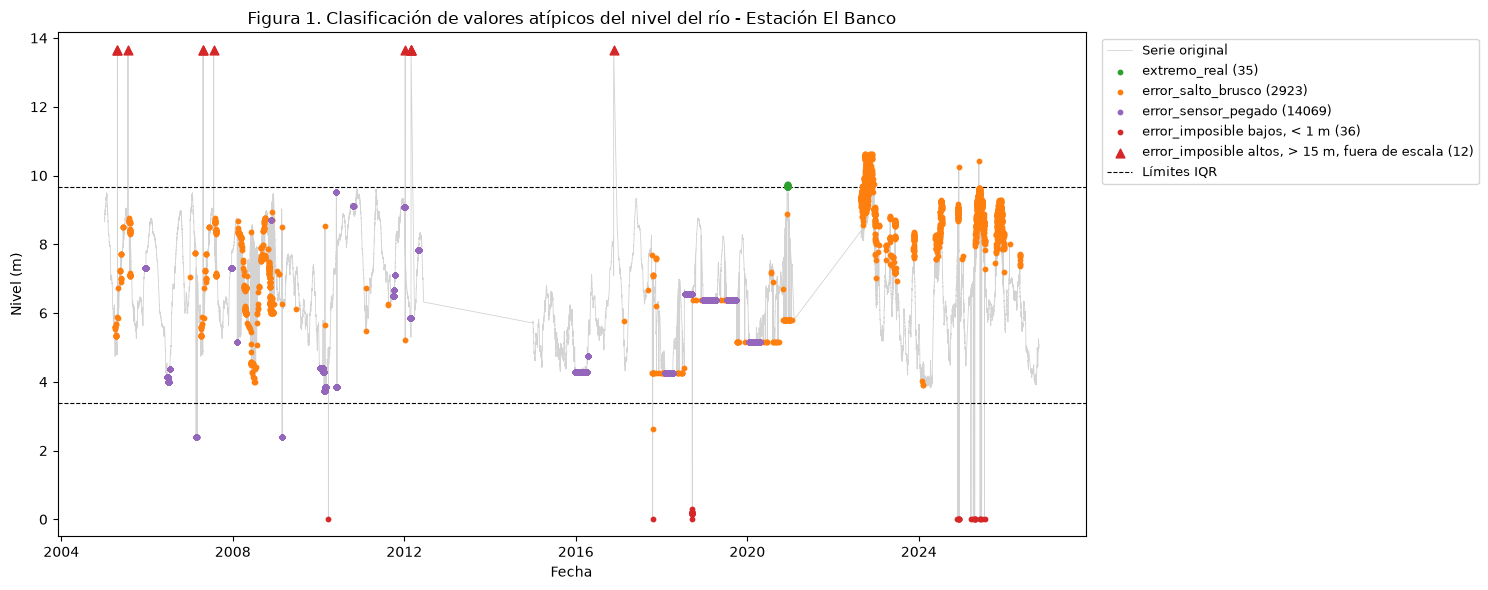

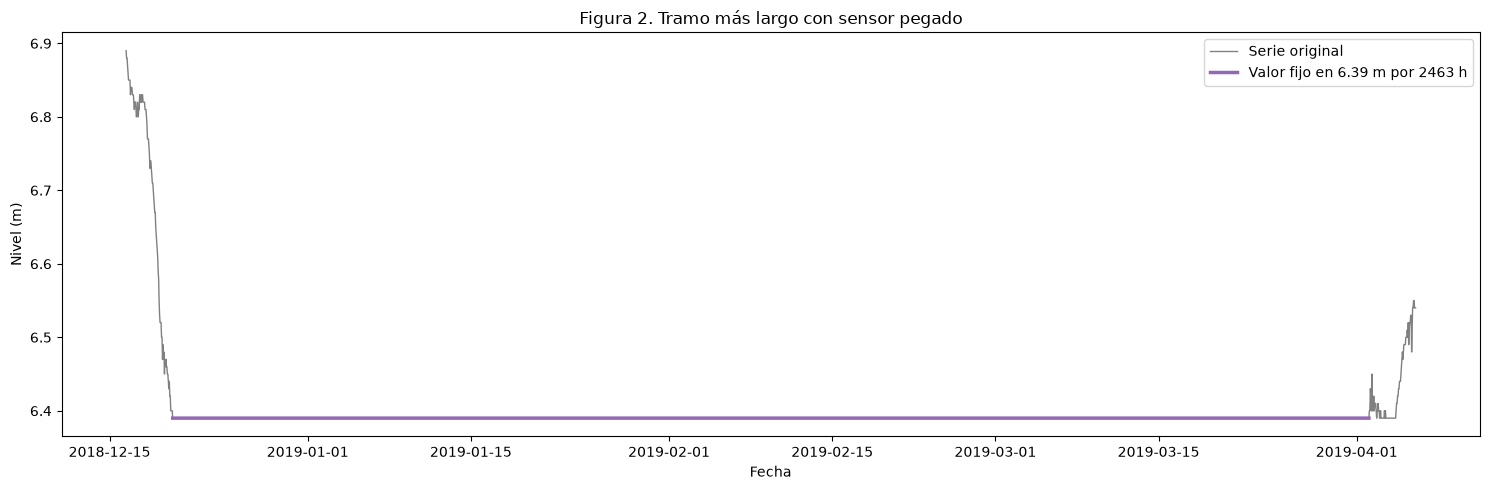

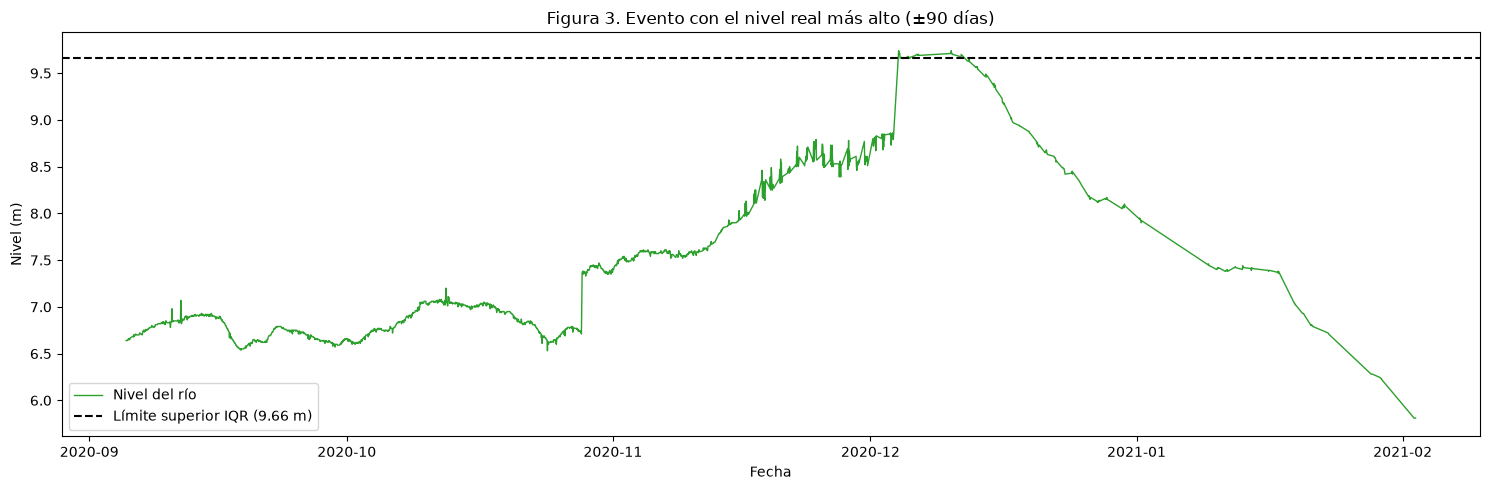

In [14]:
colores = {
    "extremo_real": "#2ca02c",
    "error_salto_brusco": "#ff7f0e",
    "error_sensor_pegado": "#9467bd",
    "error_imposible": "#d62728",
}
tope_y = limite_superior + 4  

# Figura 1: serie completa con cada tipo de atípico marcado
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df["FechaObservacion"], df["ValorObservado"].clip(upper=tope_y),
        color="lightgray", linewidth=0.6, label="Serie original")
for tipo, color in colores.items():
    sub = df[df["tipo_atipico"] == tipo]
    if tipo == "error_imposible":
        # Los imposibles altos (> 15 m) no caben en la escala: se dibujan como triángulos en el borde superior
        altos = sub[sub["ValorObservado"] > tope_y]
        bajos = sub[sub["ValorObservado"] <= tope_y]
        ax.scatter(bajos["FechaObservacion"], bajos["ValorObservado"], s=10, color=color,
                   label=f"{tipo} bajos, < 1 m ({len(bajos)})", zorder=3)
        ax.scatter(altos["FechaObservacion"], [tope_y] * len(altos), s=40, marker="^", color=color,
                   label=f"{tipo} altos, > 15 m, fuera de escala ({len(altos)})", zorder=3)
    else:
        ax.scatter(sub["FechaObservacion"], sub["ValorObservado"], s=10, color=color,
                   label=f"{tipo} ({len(sub)})", zorder=3)
ax.axhline(limite_superior, color="black", linestyle="--", linewidth=0.8, label="Límites IQR")
ax.axhline(limite_inferior, color="black", linestyle="--", linewidth=0.8)
ax.set_ylim(-0.5, tope_y + 0.5)
ax.set_title("Figura 1. Clasificación de valores atípicos del nivel del río - Estación El Banco")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.show()

# Figura 2: acercamiento al tramo más largo con sensor pegado
t = tramos_pegados.sort_values("duracion_h").iloc[-1]
ventana = df[(df["FechaObservacion"] >= t["inicio"] - pd.Timedelta(days=4)) &
             (df["FechaObservacion"] <= t["fin"] + pd.Timedelta(days=4))]
pegados = ventana[ventana["pegado"]]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(ventana["FechaObservacion"], ventana["ValorObservado"], color="gray", linewidth=1, label="Serie original")
ax.plot(pegados["FechaObservacion"], pegados["ValorObservado"], color="#9467bd", linewidth=2.5,
        label=f"Valor fijo en {t['valor']} m por {t['duracion_h']:.0f} h")
ax.set_title("Figura 2. Tramo más largo con sensor pegado")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend()
plt.tight_layout()
plt.show()

# Figura 3: evento con el extremo real más alto (±90 días), sin los errores
fecha_max = extremos.loc[extremos["ValorObservado"].idxmax(), "FechaObservacion"]
ventana = df[(df["FechaObservacion"] >= fecha_max - pd.Timedelta(days=90)) &
             (df["FechaObservacion"] <= fecha_max + pd.Timedelta(days=90)) &
             ~df["tipo_atipico"].str.startswith("error")]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(ventana["FechaObservacion"], ventana["ValorObservado"], color="#2ca02c", linewidth=1, label="Nivel del río")
ax.axhline(limite_superior, color="black", linestyle="--", label=f"Límite superior IQR ({limite_superior:.2f} m)")
ax.set_title("Figura 3. Evento con el nivel real más alto (±90 días)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend()
plt.tight_layout()
plt.show()

**Figura 1.** Los errores aparecen a lo largo de todo el periodo, pero cada tipo tiene un patrón distinto. Los tramos con sensor pegado se ven como líneas horizontales, sobre todo entre 2015 y 2020 (por ejemplo, en 4.27 m, 5.15 m, 6.39 m y 6.55 m), con valores que están dentro de los límites del IQR. Los saltos bruscos se concentran entre 2007 y 2009 y desde finales de 2022, cuando el sensor empezó a medir con más frecuencia. Los valores imposibles altos (mayores a 15 m, hasta 172.42 m) no caben en la escala de la gráfica: la serie sube hasta el borde superior y el punto se marca con un triángulo para indicar que el valor real está fuera del rango mostrado. Los imposibles bajos aparecen cerca de 0 m, sobre todo en 2018, 2024 y 2025. También se ven periodos largos sin datos, marcados por líneas rectas: entre mediados de 2012 y 2015, y entre 2021 y agosto de 2022.

**Figura 2.** El tramo pegado más largo muestra el nivel bajando de forma natural hasta 6.39 m a mediados de diciembre de 2018 y luego una línea completamente plana durante 2463 horas, hasta inicios de abril de 2019, cuando el valor vuelve a cambiar. Esto es muy distinto del comportamiento normal de la serie, en la que el mismo valor rara vez se repite más de 24 horas.

**Figura 3.** El evento con el nivel real más alto corresponde a la creciente de finales de 2020. El río sube desde unos 6.5 m en septiembre hasta cerca de 9.7 m a inicios de diciembre, se mantiene en ese nivel durante varios días y luego desciende de forma continua durante dos meses, hasta unos 5.8 m en febrero de 2021. En la subida se ven dos tramos en los que el nivel aumenta más rápido, a finales de octubre y a finales de noviembre. Aun así, el comportamiento general (un ascenso de semanas, varios días en la cima y un descenso lento y sostenido) es el de una creciente real, a diferencia de los errores del sensor, que suben y bajan en cuestión de horas. Por eso estos valores se conservan aunque superen el límite del IQR.

### **Tratamiento de los errores**
Los registros clasificados como error se convierten en valores nulos en lugar de eliminar las filas. Así se conserva la línea de tiempo completa y queda marcado que en esa fecha no hay un dato confiable. Si se eliminaran las filas, las fechas que quedan aparecerían como consecutivas aunque entre ellas falten horas o días, lo cual afectaría la construcción de variables basadas en el pasado. Los extremos reales no se modifican.

Los huecos que dejan los errores se pueden rellenar con interpolación lineal, es decir, trazando una línea recta entre el último dato válido antes del hueco y el primero después. Esto solo tiene sentido en huecos cortos, donde el río no alcanza a cambiar mucho; en huecos largos, una línea recta inventaría un comportamiento que no se observó. Para decidir hasta qué tamaño de hueco se puede interpolar, se midió el error que comete la interpolación sobre datos reales: se toman mediciones que sí existen, se estiman con una línea recta entre el dato de antes y el de después como si no estuvieran, y se compara la estimación con el valor real.

In [15]:
# Error que comete la interpolación lineal según el tamaño del hueco
validos = df[~df["tipo_atipico"].str.startswith("error")].set_index("FechaObservacion")["ValorObservado"]
validos = validos[~validos.index.duplicated()]
horario = validos[validos.index.minute == 0]  # solo mediciones en hora exacta, para comparar en la misma escala

print("Error al estimar un valor con una línea recta entre el dato anterior y el siguiente:")
for h in [2, 4, 6, 8, 12, 24]:
    mitad = pd.Timedelta(hours=h / 2)
    antes = horario.reindex(horario.index - mitad).to_numpy()
    despues = horario.reindex(horario.index + mitad).to_numpy()
    estimado = (antes + despues) / 2  # punto medio de la línea recta
    error = np.abs(horario.to_numpy() - estimado)
    error = error[~np.isnan(error)]
    print(f"   hueco de {h:>2} h: mediana {np.median(error):.3f} m | percentil 95 {np.percentile(error, 95):.3f} m"
          f" | casos evaluados {len(error)}")

Error al estimar un valor con una línea recta entre el dato anterior y el siguiente:
   hueco de  2 h: mediana 0.005 m | percentil 95 0.025 m | casos evaluados 127761
   hueco de  4 h: mediana 0.005 m | percentil 95 0.025 m | casos evaluados 126824
   hueco de  6 h: mediana 0.005 m | percentil 95 0.025 m | casos evaluados 126016
   hueco de  8 h: mediana 0.005 m | percentil 95 0.030 m | casos evaluados 125419
   hueco de 12 h: mediana 0.005 m | percentil 95 0.030 m | casos evaluados 124599
   hueco de 24 h: mediana 0.010 m | percentil 95 0.045 m | casos evaluados 123393


La mitad de las estimaciones se equivoca 0.5 cm o menos para huecos de hasta 12 horas. El percentil 95 se mantiene en 2.5 cm para huecos de 2, 4 y 6 horas, y a partir de 8 horas empieza a crecer (3 cm con 8 y 12 horas, y 4.5 cm con 24 horas). Por eso se tomó 6 horas como límite: es el hueco más grande que se puede rellenar sin que el error aumente respecto al de un hueco de 2 horas. Los huecos de más de 6 horas se dejan vacíos. Esta evaluación estima el punto ubicado en la mitad del hueco, que es donde la línea recta suele alejarse más del valor real, por lo que representa el caso menos favorable.

El límite se mide en tiempo y no en número de filas porque el sensor no siempre mide con la misma frecuencia (a veces cada hora, a veces cada 10 minutos). Con un límite en filas, 6 registros serían 6 horas en unos periodos y solo 1 hora en otros. Por la misma razón se usa `method="time"`, que tiene en cuenta cuánto tiempo pasó entre los datos.

In [16]:
# Se guarda una copia con la clasificación por si se necesita más adelante
df_clasificado = df.copy()

# Los errores se convierten en nulos. Los extremos reales NO se tocan
es_error = df["tipo_atipico"].str.startswith("error")
df["ValorObservado"] = df["ValorObservado"].mask(es_error)
print(f"Errores convertidos en nulos: {es_error.sum()}")

# Interpolación solo en huecos cortos, medidos en TIEMPO y no en número de filas
MAX_HUECO = pd.Timedelta(hours=6)  

serie = df.set_index("FechaObservacion")["ValorObservado"]
es_nulo = serie.isna()
tiempos = serie.index.to_series()
anterior_valido = tiempos.where(~es_nulo).ffill()   
siguiente_valido = tiempos.where(~es_nulo).bfill()  
duracion_hueco = siguiente_valido - anterior_valido

rellenable = es_nulo & (duracion_hueco <= MAX_HUECO)
interpolada = serie.interpolate(method="time", limit_area="inside")
df["ValorObservado"] = serie.where(~rellenable, interpolada).to_numpy()

print(f"Nulos rellenados por interpolación (huecos de hasta {MAX_HUECO}): {rellenable.sum()}")
print(f"Nulos que quedan (huecos largos, se dejan vacíos): {df['ValorObservado'].isna().sum()}")

# Se dejan solo las dos columnas originales para los pasos siguientes
df = df[["FechaObservacion", "ValorObservado"]]
display(df["ValorObservado"].describe().to_frame().T)

Errores convertidos en nulos: 17040
Nulos rellenados por interpolación (huecos de hasta 0 days 06:00:00): 2568
Nulos que quedan (huecos largos, se dejan vacíos): 14472


,count,mean,std,min,25%,50%,75%,max
ValorObservado,283350.0,6.586679,1.2424,3.82,5.79,6.55,7.36,9.74


Se convirtieron en nulos 17040 errores (48 imposibles, 14069 de sensor pegado y 2923 saltos bruscos). De ellos, 2568 se rellenaron por interpolación y 14472 quedaron vacíos por pertenecer a huecos largos, principalmente los tramos de sensor pegado que duraron semanas o meses. Los vacíos no afectan la agregación diaria o semanal, porque el promedio con `.mean()` ignora los valores nulos, pero sí dejan semanas sin datos que se deben tener en cuenta al construir las variables de rezago.

Después del tratamiento, el nivel queda entre 3.82 m y 9.74 m, con una media de 6.59 m y una mediana de 6.55 m. El máximo de 9.74 m corresponde a la creciente real de diciembre de 2020, que se conservó. La desviación estándar bajó de 1.40 m a 1.24 m, porque ya no la inflan valores imposibles como 172.42 m. Además, la media y la mediana quedaron casi iguales, lo que indica que la distribución ya no está distorsionada por valores extremos erróneos.

**Limitación:** en algunos periodos, por ejemplo en agosto de 2005, el nivel cambia de golpe cerca de un metro y se queda en el nuevo valor, en lugar de volver al anterior. Esto sugiere un cambio en la referencia del sensor (reinstalación o recalibración) más que un cambio real del río. Como no es posible saber cuál de los dos niveles es el correcto, estos escalones no se corrigieron y se dejan como una limitación de los datos.

# **1.5. Frecuencia real de los registros**
El conjunto de datos no indica cada cuánto mide el sensor, así que la frecuencia real se determina a partir de los datos: para cada registro se calcula cuánto tiempo pasó desde el registro anterior. Si el sensor midiera siempre con la misma frecuencia, todas estas diferencias serían iguales. Las diferencias distintas revelan cambios en la frecuencia de medición, varias observaciones por hora o periodos sin información.

Este análisis se hace sobre las fechas de todos los registros recibidos, incluidos los que se marcaron como error, porque lo que se quiere conocer es cada cuánto envía datos el sensor, no cuántos de esos datos son confiables.

In [17]:
# Diferencia de tiempo entre cada registro y el anterior
diferencias = df["FechaObservacion"].diff()

print("Intervalos más frecuentes entre registros consecutivos:")
display(diferencias.value_counts().head(10).to_frame("registros"))

# Se agrupan los intervalos en rangos para ver el panorama general
rangos = pd.cut(
    diferencias.dt.total_seconds() / 60,
    bins=[0, 10, 60, 6 * 60, 24 * 60, np.inf],
    labels=["Hasta 10 min", "Más de 10 min hasta 1 h", "Más de 1 h hasta 6 h",
            "Más de 6 h hasta 1 día", "Más de 1 día"],
)
print("\nIntervalos agrupados por rango:")
display(rangos.value_counts(sort=False).to_frame("intervalos"))

# Intervalo más común en cada año: muestra si la frecuencia del sensor cambió con el tiempo
intervalo_por_año = (
    pd.DataFrame({"año": df["FechaObservacion"].dt.year, "minutos": diferencias.dt.total_seconds() / 60})
    .groupby("año")["minutos"]
    .agg(lambda s: s.mode().iloc[0])
)
print("\nIntervalo más común por año (minutos):")
display(intervalo_por_año.to_frame("intervalo_mas_comun_min").T)

Intervalos más frecuentes entre registros consecutivos:


,registros
FechaObservacion,
0 days 00:10:00,181728
0 days 01:00:00,114603
0 days 00:40:00,527
0 days 00:20:00,193
0 days 02:00:00,112
0 days 01:10:00,81
0 days 00:30:00,44
0 days 05:00:00,35
0 days 01:40:00,21



Intervalos agrupados por rango:


,intervalos
FechaObservacion,
Hasta 10 min,181823
Más de 10 min hasta 1 h,115379
Más de 1 h hasta 6 h,359
Más de 6 h hasta 1 día,197
Más de 1 día,63



Intervalo más común por año (minutos):


año,2005,2006,2007,2008,2009,2010,2011,2012,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
intervalo_mas_comun_min,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,10.0,10.0,10.0,10.0,10.0


El intervalo más común entre registros es de 10 minutos (181728 casos), seguido de 1 hora (114603 casos). La tabla por año muestra que no se trata de una mezcla al azar, sino de un cambio en la operación del sensor: entre 2005 y 2021 la medición fue horaria, y desde 2022 el sensor registra cada 10 minutos. Como consecuencia, más de la mitad de los registros del conjunto corresponden a los últimos cinco años, aunque el periodo horario abarca unos diecisiete. Los años 2013 y 2014 no aparecen en la tabla porque no tienen ningún registro.

Además de estas dos frecuencias, aparecen intervalos de 20, 30 y 40 minutos, que corresponden a mediciones faltantes dentro de los periodos de 10 minutos. Al agrupar los intervalos por rango, se encontraron 359 interrupciones de entre 1 y 6 horas, 197 de entre 6 horas y un día, y 63 de más de un día. Es decir, existen tanto múltiples observaciones por hora (desde 2022) como periodos sin información de distinta duración.

Que la frecuencia no sea constante tiene una consecuencia para los pasos siguientes: si se promedian directamente los registros de un día, las horas medidas cada 10 minutos pesan seis veces más que las horas medidas una vez. Por eso, antes de agregar por día o por semana, la serie se lleva primero a una frecuencia horaria.

In [18]:
# Registros por día y días completos sin información
registros_por_dia = df["FechaObservacion"].dt.date.value_counts().sort_index()
todos_los_dias = pd.date_range(df["FechaObservacion"].min().normalize(),
                               df["FechaObservacion"].max().normalize(), freq="D")

print(f"Días en el periodo de estudio: {len(todos_los_dias)}")
print(f"Días con al menos un registro: {len(registros_por_dia)}")
print(f"Días sin ningún registro: {len(todos_los_dias) - len(registros_por_dia)}")

print("\nResumen de registros por día (solo días con datos):")
display(registros_por_dia.describe().to_frame("registros_por_dia").T)

# Periodos sin información de más de un día
saltos = diferencias > pd.Timedelta(days=1)
periodos_sin_info = pd.DataFrame({
    "inicio": df["FechaObservacion"].shift()[saltos],
    "fin": df["FechaObservacion"][saltos],
    "duracion": diferencias[saltos],
}).sort_values("duracion", ascending=False)

print(f"\nPeriodos sin información de más de un día: {len(periodos_sin_info)}")
print("Los 10 más largos:")
display(periodos_sin_info.head(10))

Días en el periodo de estudio: 7962
Días con al menos un registro: 6259
Días sin ningún registro: 1703

Resumen de registros por día (solo días con datos):


,count,mean,std,min,25%,50%,75%,max
registros_por_dia,6259.0,47.583,47.39327,1.0,24.0,24.0,24.0,146.0



Periodos sin información de más de un día: 63
Los 10 más largos:


,inicio,fin,duracion
64129,2012-06-14 00:00:00,2015-01-01 01:00:00,931 days 01:00:00
113365,2021-02-02 12:00:00,2022-08-26 21:20:00,570 days 09:20:00
62269,2012-02-27 08:00:00,2012-03-27 18:00:00,29 days 10:00:00
79689,2016-11-18 12:00:00,2016-12-17 14:00:00,29 days 02:00:00
226995,2025-02-04 23:50:00,2025-02-26 00:00:00,21 days 00:10:00
296269,2026-07-24 23:00:00,2026-08-12 00:00:00,18 days 01:00:00
81654,2017-03-14 01:00:00,2017-03-27 20:00:00,13 days 19:00:00
113291,2021-01-01 15:00:00,2021-01-09 08:00:00,7 days 17:00:00
121335,2022-11-20 23:50:00,2022-11-28 00:00:00,7 days 00:10:00
122215,2022-12-07 08:00:00,2022-12-14 00:00:00,6 days 16:00:00


De los 7962 días del periodo de estudio, 6259 tienen al menos un registro y 1703 no tienen ninguno, es decir, cerca del 21 % del periodo no tiene información. Estos días no aparecen como valores nulos en el conjunto original, simplemente no existen filas para ellos, por lo que no se detectaron en la revisión inicial de faltantes.

La mayor parte de estos días se concentra en dos periodos largos sin información: del 14 de junio de 2012 al 1 de enero de 2015 (931 días) y del 2 de febrero de 2021 al 26 de agosto de 2022 (570 días). Juntos suman cerca del 88 % de los días sin registros. Además, hay otros 61 periodos de más de un día sin información, la mayoría de menos de un mes. Esto significa que la serie no es continua, sino que está formada por varios bloques separados, lo que debe tenerse en cuenta al construir variables basadas en semanas anteriores.

En los días con datos, la mediana es de 24 registros, es decir, un día típico tiene una medición por hora. La media (47.6) es casi el doble de la mediana porque desde 2022 el sensor mide cada 10 minutos, con hasta 144 registros por día. También hay días con muy pocos registros (el mínimo es 1), cuyos promedios diarios son menos confiables; por eso en la agregación se calcula la cobertura de cada periodo.

# **1.6. Agregación diaria y semanal**
Se construyen dos agregaciones exploratorias del nivel del río: el promedio diario y el promedio semanal. Las decisiones del proceso son:

- **Primero se lleva la serie a frecuencia horaria.** Se promedian los registros de cada hora y luego se calcula el promedio diario o semanal a partir de esas horas. Así cada hora pesa lo mismo, sin importar si el sensor midió una vez o seis veces en ella.
- **Semanas de lunes a domingo** (`W-SUN`): cada semana termina el domingo, como se vio en clase.
- **Los valores nulos se ignoran.** El promedio con `.mean()` solo usa los datos válidos de cada periodo. Un periodo sin ningún dato válido queda vacío.
- **Se calcula la cobertura de cada periodo**, es decir, qué fracción de sus horas tiene datos válidos (un día tiene 24 horas y una semana 168). Un promedio calculado con pocas horas es menos confiable que uno con el periodo completo, y esta información se usará más adelante para decidir qué periodos se aceptan al preparar los datos para el modelo.

In [19]:
serie = df.set_index("FechaObservacion")["ValorObservado"]

# Frecuencia horaria: promedio de los registros de cada hora
serie_horaria = serie.resample("h").mean()

# Agregaciones a partir de las horas
df_diario = serie_horaria.resample("D").mean()
df_semanal = serie_horaria.resample("W-SUN").mean()

# Cobertura: fracción de horas con datos válidos en cada periodo
cobertura_diaria = serie_horaria.resample("D").count() / 24
cobertura_semanal = serie_horaria.resample("W-SUN").count() / 168

resumen = pd.DataFrame({
    "periodos_totales": [len(df_diario), len(df_semanal)],
    "con_datos": [df_diario.notna().sum(), df_semanal.notna().sum()],
    "vacios": [df_diario.isna().sum(), df_semanal.isna().sum()],
    "cobertura_mediana_%": [cobertura_diaria[df_diario.notna()].median() * 100,
                            cobertura_semanal[df_semanal.notna()].median() * 100],
}, index=["Diaria", "Semanal"]).round(1)
display(resumen)

print("Cobertura de los periodos con datos (fracción de horas con datos válidos):")
display(pd.DataFrame({
    "Diaria": cobertura_diaria[df_diario.notna()].describe(),
    "Semanal": cobertura_semanal[df_semanal.notna()].describe(),
}).round(3).T)

print("\nPrimeros registros de la agregación diaria:")
display(df_diario.head().to_frame("nivel_promedio_diario"))
print("Primeros registros de la agregación semanal:")
display(df_semanal.head().to_frame("nivel_promedio_semanal"))

,periodos_totales,con_datos,vacios,cobertura_mediana_%
Diaria,7962,5709,2253,100.0
Semanal,1139,855,284,100.0


Cobertura de los periodos con datos (fracción de horas con datos válidos):


,count,mean,std,min,25%,50%,75%,max
Diaria,5709.0,0.961,0.151,0.042,1.000,1.0,1.0,1.0
Semanal,855.0,0.916,0.207,0.006,0.976,1.0,1.0,1.0



Primeros registros de la agregación diaria:


,nivel_promedio_diario
FechaObservacion,
2005-01-01,8.664286
2005-01-02,8.683750
2005-01-03,8.724167
2005-01-04,8.767917
2005-01-05,8.803333


Primeros registros de la agregación semanal:


,nivel_promedio_semanal
FechaObservacion,
2005-01-02,8.679355
2005-01-09,8.856131
2005-01-16,9.124583
2005-01-23,9.411786
2005-01-30,9.091845


La agregación diaria produce 7962 periodos, de los cuales 5709 tienen datos y 2253 quedan vacíos. La agregación semanal produce 1139 periodos, de los cuales 855 tienen datos y 284 quedan vacíos. Es decir, la agregación semanal reduce la cantidad de puntos unas 7 veces.

El número de días con datos (5709) es menor que el de días con registros encontrado en la sección anterior (6259), porque 550 días solo tenían registros clasificados como error, por ejemplo durante los meses en que el sensor permaneció pegado, y al convertirlos en nulos esos días quedaron sin datos válidos.

En cuanto a la cobertura, la mayoría de los periodos están completos: la mediana es del 100 % tanto en la agregación diaria como en la semanal, y al menos el 75 % de los días y de las semanas con datos tienen el 100 % y el 97.6 % de sus horas, respectivamente. Sin embargo, existen periodos con muy poca información, como días con solo una hora de datos (4 % de cobertura) y semanas con una sola hora (0.6 %). El promedio de esos periodos depende de muy pocos datos y puede no representar el nivel real del río en ese día o semana, por lo que más adelante se debe definir una cobertura mínima para aceptar un periodo.

Ninguna de las dos agregaciones es mejor en todo. La diaria conserva más detalle y más puntos para entrenar, pero también más variación de corto plazo. La semanal produce menos puntos, pero suaviza las variaciones y es menos sensible a días con pocos datos.

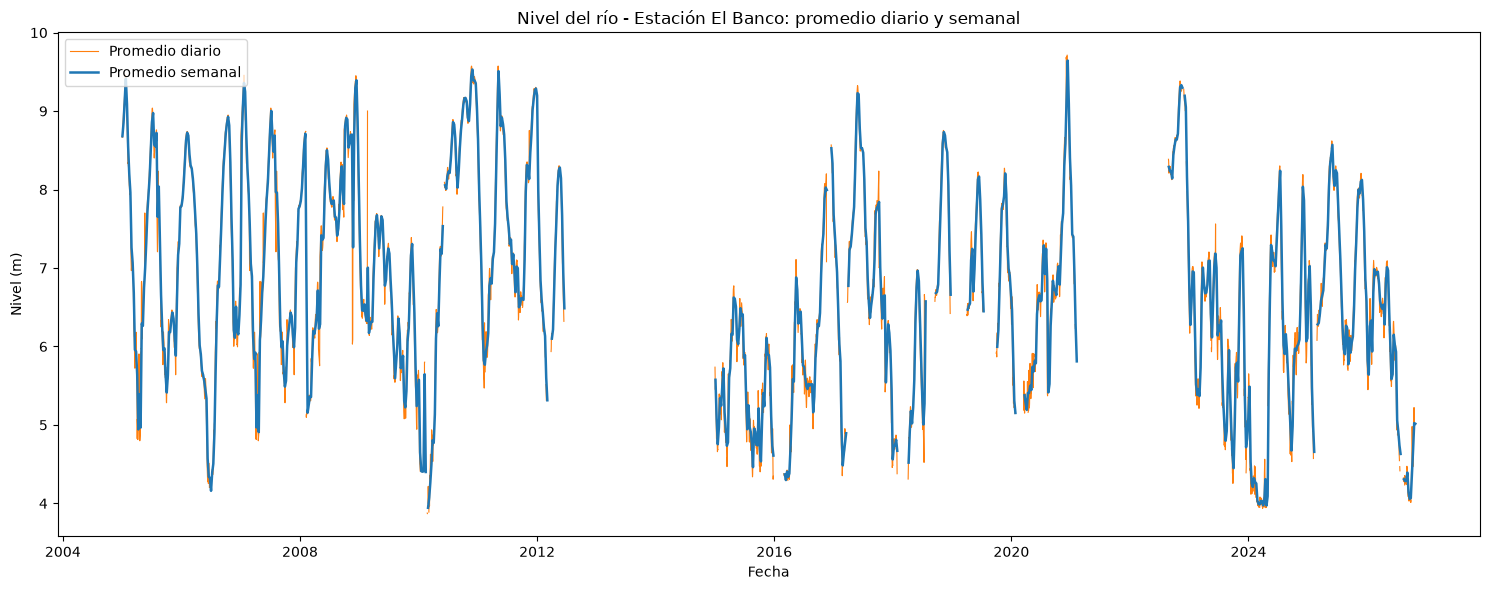

In [20]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df_diario.index, df_diario.values, color="#ff7f0e", linewidth=0.8, label="Promedio diario")
ax.plot(df_semanal.index, df_semanal.values, color="#1f77b4", linewidth=1.8, label="Promedio semanal")
ax.set_title("Nivel del río - Estación El Banco: promedio diario y semanal")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

La gráfica muestra que la serie está formada por tres bloques separados por los dos grandes periodos sin información: de 2005 a mediados de 2012, de 2015 a inicios de 2021 y de agosto de 2022 a 2026. Los cortes más pequeños dentro de cada bloque corresponden a días o semanas sin datos válidos. Matplotlib no une puntos separados por valores nulos, por lo que estos vacíos se ven como interrupciones en las líneas.

El nivel del río tiene un comportamiento cíclico: sube y baja varias veces dentro de cada año, aproximadamente entre 4 m y 9.5 m. El nivel más alto, cercano a 9.7 m, corresponde a la creciente de finales de 2020, y los más bajos, cercanos a 4 m, se presentan alrededor de 2010 y en 2024. Que este patrón se repita año tras año indica que la época del año aporta información para predecir el nivel.

La línea semanal sigue de cerca a la diaria: conserva las subidas y bajadas importantes del río y solo suaviza las variaciones de pocos días. Esto indica que la agregación semanal no pierde el comportamiento principal de la serie, aunque reduce la cantidad de puntos disponibles.

# **1.7. Comportamiento temporal de la serie**
Para observar la evolución de la serie se eligió la agregación semanal, que será la usada en el resto del proyecto. La comparación de la sección anterior mostró que la serie semanal conserva las subidas y bajadas importantes del río y solo suaviza las variaciones de pocos días, que no son el objetivo de la predicción. Además, es menos sensible a días con pocos datos, porque cada promedio semanal se calcula con hasta 168 horas. A cambio, produce menos puntos: 855 semanas con datos frente a 5709 días.

Sobre la serie semanal se dibuja una media móvil de 52 semanas (un año), centrada. Como cada punto de esta línea promedia un año completo, las subidas y bajadas propias de cada época del año se cancelan, y lo que queda es la tendencia de largo plazo. Se exige que al menos 26 de las 52 semanas tengan datos para calcularla. También se sombrean los periodos de 4 semanas o más sin datos.

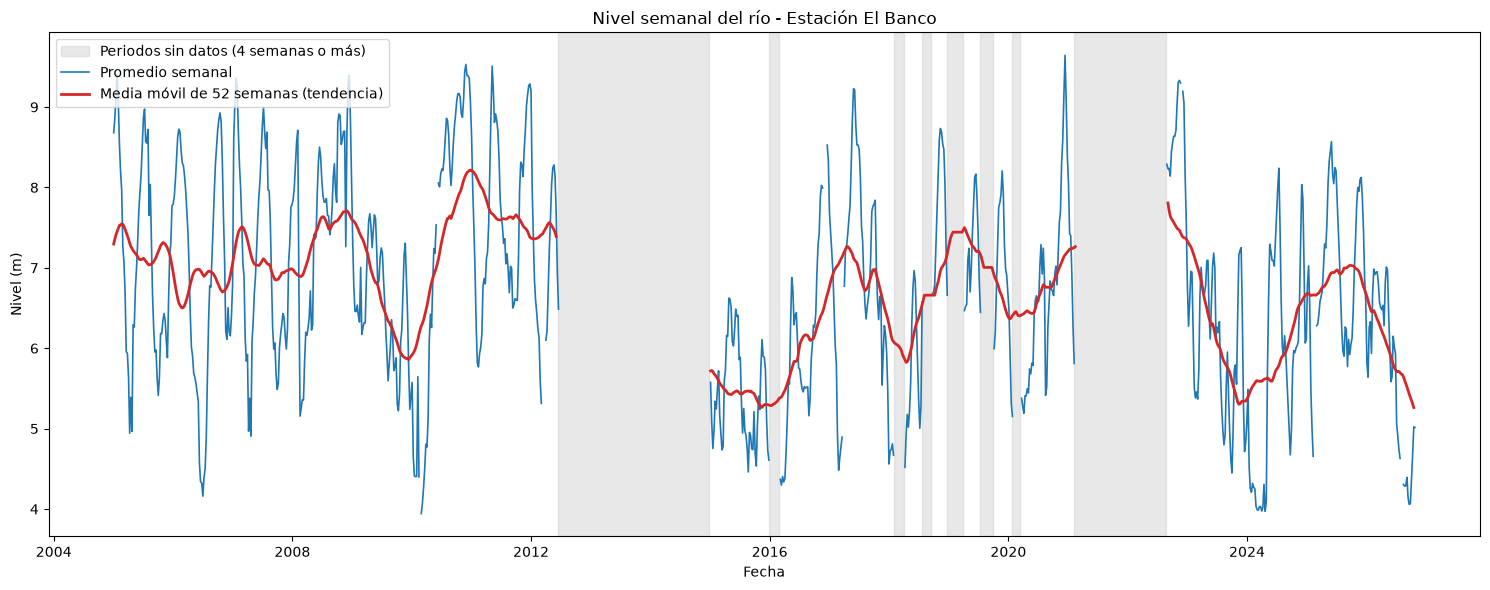

Periodos de 4 semanas o más sin datos: 8


,primera_semana_vacia,ultima_semana_vacia,semanas
0,2012-06-24,2014-12-28,132
1,2021-02-14,2022-08-21,80
2,2018-12-30,2019-03-31,14
3,2019-07-21,2019-09-29,11
4,2016-01-03,2016-02-28,9
5,2018-02-04,2018-04-01,9
6,2018-07-29,2018-09-16,8
7,2020-02-02,2020-03-15,7


Nivel promedio por año (y semanas con datos):


FechaObservacion,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
nivel_promedio,7.12,6.91,7.11,7.64,6.53,7.34,7.6,7.07,NaN,NaN,...,6.91,6.43,7.19,6.64,6.97,8.64,6.04,5.76,6.98,5.71
semanas_con_datos,52.00,53.00,52.00,52.00,52.00,50.00,52.0,22.00,0.0,0.0,...,52.00,34.00,28.00,45.00,6.00,17.00,53.00,52.00,50.00,41.00


In [21]:
# Tendencia: media móvil centrada de 52 semanas (al menos 26 semanas con datos)
tendencia = df_semanal.rolling(52, center=True, min_periods=26).mean()

# Periodos de 4 semanas o más sin datos
vacia = df_semanal.isna()
grupo = (vacia != vacia.shift()).cumsum()
tramos_vacios = df_semanal[vacia].index.to_series().groupby(grupo[vacia]).agg(["min", "max", "size"])
tramos_vacios = tramos_vacios[tramos_vacios["size"] >= 4]

fig, ax = plt.subplots(figsize=(15, 6))
for i, (_, t) in enumerate(tramos_vacios.iterrows()):
    ax.axvspan(t["min"] - pd.Timedelta(days=7), t["max"], color="lightgray", alpha=0.5,
               label="Periodos sin datos (4 semanas o más)" if i == 0 else None)
ax.plot(df_semanal.index, df_semanal.values, color="#1f77b4", linewidth=1.2, label="Promedio semanal")
ax.plot(tendencia.index, tendencia.values, color="#d62728", linewidth=2, label="Media móvil de 52 semanas (tendencia)")
ax.set_title("Nivel semanal del río - Estación El Banco")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Periodos de 4 semanas o más sin datos: {len(tramos_vacios)}")
display(tramos_vacios.rename(columns={"min": "primera_semana_vacia", "max": "ultima_semana_vacia",
                                      "size": "semanas"}).sort_values("semanas", ascending=False).reset_index(drop=True))

print("Nivel promedio por año (y semanas con datos):")
display(df_semanal.groupby(df_semanal.index.year).agg(nivel_promedio="mean", semanas_con_datos="count").round(2).T)

Para revisar si existe estacionalidad, es decir, un patrón que se repite en las mismas épocas de cada año, se agrupan las semanas por mes y se dibuja un diagrama de caja para cada mes. Si el nivel dependiera de la época del año, las cajas de unos meses estarían claramente más arriba o más abajo que las de otros.

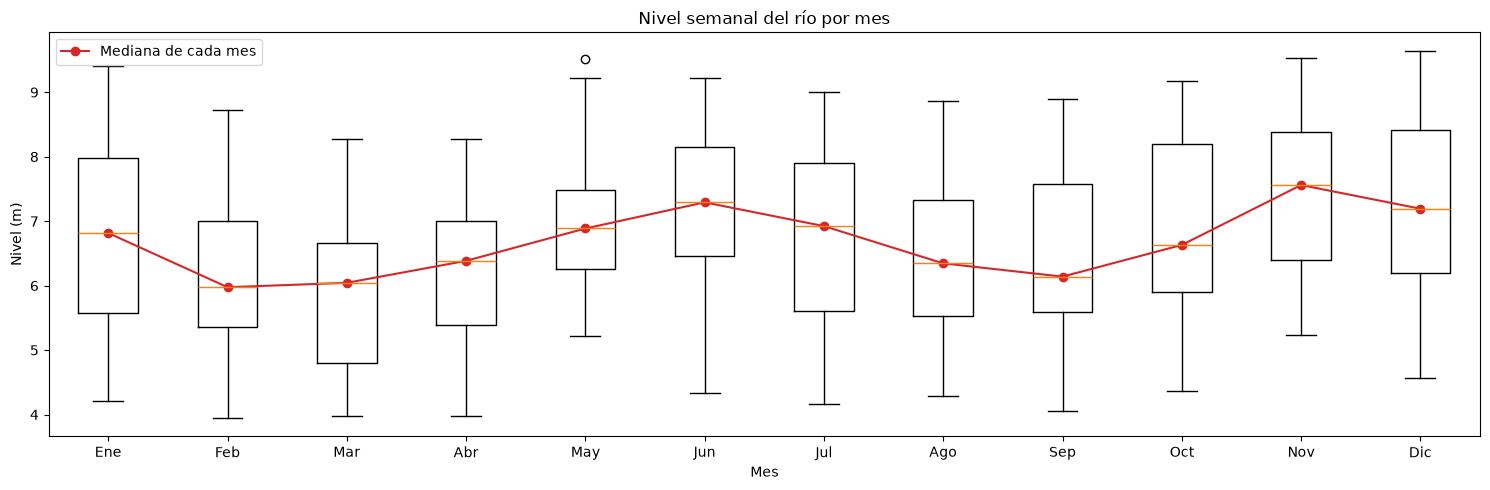

mes,1,2,3,4,5,6,7,8,9,10,11,12
semanas,76.00,54.00,64.00,77.00,80.00,74.00,73.00,66.00,68.00,80.00,71.00,72.00
mediana,6.82,5.97,6.04,6.38,6.89,7.29,6.92,6.34,6.14,6.63,7.56,7.19
minimo,4.21,3.94,3.97,3.97,5.22,4.33,4.16,4.28,4.06,4.36,5.24,4.56
maximo,9.41,8.72,8.27,8.27,9.51,9.22,9.00,8.86,8.90,9.17,9.53,9.64


In [22]:
semanas = df_semanal.dropna().to_frame("nivel")
semanas["mes"] = semanas.index.month
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
datos_por_mes = [semanas.loc[semanas["mes"] == m, "nivel"] for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(15, 5))
ax.boxplot(datos_por_mes)
ax.set_xticklabels(meses)
ax.plot(range(1, 13), [d.median() for d in datos_por_mes], color="#d62728", marker="o", label="Mediana de cada mes")
ax.set_title("Nivel semanal del río por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Nivel (m)")
ax.legend()
plt.tight_layout()
plt.show()

display(semanas.groupby("mes")["nivel"].agg(semanas="size", mediana="median", minimo="min", maximo="max").round(2).T)

**Estacionalidad.** El diagrama de caja por mes muestra un patrón que se repite cada año, con dos periodos de niveles altos y dos de niveles bajos. Los niveles más altos se presentan entre mayo y julio (mediana máxima en junio, 7.29 m) y entre noviembre y diciembre (mediana máxima en noviembre, 7.56 m). Los más bajos se presentan entre febrero y marzo (medianas de 5.97 m y 6.04 m) y entre agosto y septiembre (6.34 m y 6.14 m). Sin embargo, las cajas de los distintos meses se traslapan bastante y en casi todos los meses el nivel varía entre unos 4 m y 9 m, lo que indica que la época del año explica parte del comportamiento del río, pero no todo: el mismo mes puede presentar niveles altos en un año y bajos en otro.

**Tendencia.** La media móvil de 52 semanas no muestra un aumento ni una disminución sostenida del nivel a lo largo de los 21 años. En cambio, oscila entre unos 5.3 m y 8.2 m, con periodos de varios años en que el río se mantiene más alto que el promedio (por ejemplo, 2010–2011, 2018–2019 y finales de 2020) y otros en que se mantiene más bajo (2009–2010, 2015–2016 y 2023–2024). Es decir, además del ciclo dentro de cada año, existen variaciones de un año a otro.

El promedio anual debe interpretarse con cuidado en los años incompletos. Por ejemplo, 2022 tiene el promedio más alto (8.64 m), pero solo cuenta con 17 semanas de datos, todas entre agosto y diciembre, que incluyen la temporada de niveles altos de fin de año; lo mismo ocurre con 2021 (6 semanas) y 2012 (22 semanas).

**Picos.** Los niveles semanales más altos, cercanos a 9.5 m, se presentan en 2005, entre 2010 y 2011, a finales de 2020 (el máximo de la serie, cerca de 9.6 m) y a finales de 2022, en todos los casos dentro de las temporadas de niveles altos identificadas en el diagrama por mes.

**Caídas.** Después de los picos, el nivel puede bajar entre 3 y 5 metros en unas pocas semanas o meses, por ejemplo en 2006, en 2010 (hasta unos 3.9 m, el mínimo de la serie) y a finales de 2023. Estas bajadas son rápidas en comparación con la duración de la serie, pero ocurren a lo largo de varias semanas y no de un día para otro, a diferencia de los saltos del sensor que se eliminaron en la limpieza.

**Periodos sin datos.** Se identificaron 8 periodos de 4 semanas o más sin datos. Los dos más largos corresponden a la ausencia de registros del sensor: de junio de 2012 a diciembre de 2014 (132 semanas) y de febrero de 2021 a agosto de 2022 (80 semanas). Los otros seis, de entre 7 y 14 semanas, ocurren entre 2016 y 2020 y coinciden con los tramos en que el sensor permaneció pegado, cuyos registros se eliminaron en la limpieza. Por lo tanto, la serie semanal está formada por tres bloques principales, y dentro del segundo bloque hay varias interrupciones de algunos meses.

# **1.8. Distribución del nivel semanal**
El histograma muestra cuántas semanas tuvieron cada nivel del río. Permite ver alrededor de qué valores se concentra el nivel, qué tan dispersos están los datos y si la distribución es simétrica o tiene una cola hacia algún lado. Se usa la serie semanal ya limpia, que es la que se usará para los modelos.

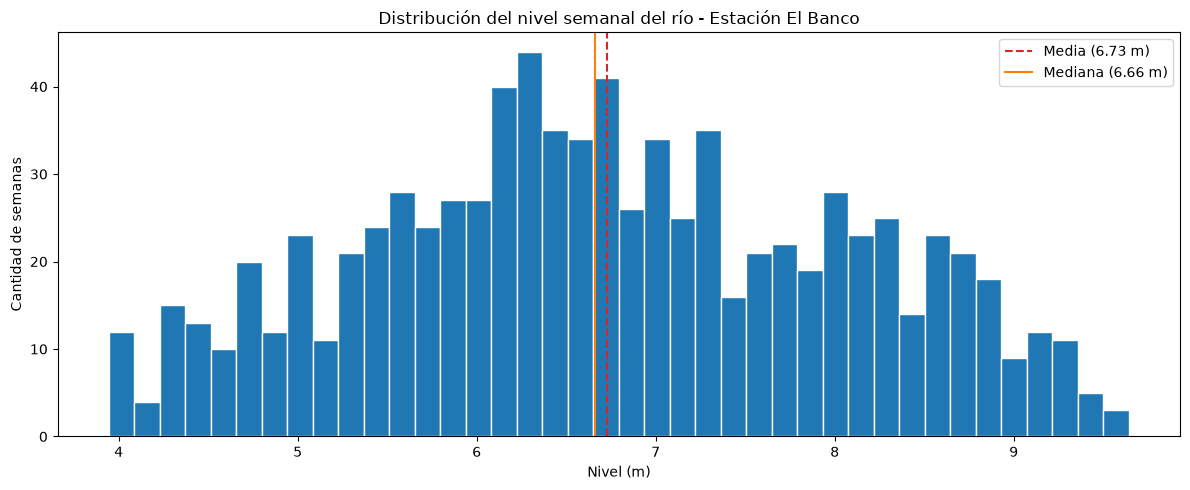

,count,mean,std,min,25%,50%,75%,max
nivel_semanal,855.0,6.73,1.33,3.94,5.77,6.66,7.78,9.64


Asimetría: 0.04


In [23]:
nivel = df_semanal.dropna()

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(nivel, bins=40, color="#1f77b4", edgecolor="white")
ax.axvline(nivel.mean(), color="#d62728", linestyle="--", label=f"Media ({nivel.mean():.2f} m)")
ax.axvline(nivel.median(), color="#ff7f0e", linestyle="-", label=f"Mediana ({nivel.median():.2f} m)")
ax.set_title("Distribución del nivel semanal del río - Estación El Banco")
ax.set_xlabel("Nivel (m)")
ax.set_ylabel("Cantidad de semanas")
ax.legend()
plt.tight_layout()
plt.show()

display(nivel.describe().to_frame("nivel_semanal").T.round(2))
print(f"Asimetría: {nivel.skew():.2f}")

El nivel semanal varía entre 3.94 m y 9.64 m. La media (6.73 m) y la mediana (6.66 m) son casi iguales y la asimetría es de 0.04, muy cercana a 0, lo que indica que la distribución es prácticamente simétrica: no tiene una cola larga hacia valores altos ni hacia valores bajos. La mitad central de las semanas está entre 5.77 m y 7.78 m, y la mayor cantidad de semanas se concentra entre 6 m y 7 m.

La distribución es amplia (desviación estándar de 1.33 m) y no tiene un solo pico marcado, lo cual es coherente con un río que pasa buena parte del año subiendo y bajando entre temporadas, en lugar de mantenerse en un nivel fijo. Como la distribución es simétrica y ya no tiene valores extremos erróneos, no es necesario aplicar transformaciones como la logarítmica, que se usan cuando los datos tienen una cola muy larga hacia un lado.

# **1.9. Correlación del nivel con las semanas anteriores**
El conjunto de datos tiene una sola variable numérica (el nivel), así que no se puede calcular una matriz de correlación entre variables distintas. En una serie de tiempo, lo que interesa es qué tanto se parece el nivel de una semana al nivel de semanas anteriores. Para medirlo, se desplaza la serie 1, 2, 3, 4, 8, 13, 26 y 52 semanas hacia atrás y se calcula la correlación de Pearson entre el nivel actual y cada versión desplazada.

La correlación de Pearson va de -1 a 1. Un valor cercano a 1 indica que, cuando una variable es alta, la otra también tiende a serlo; un valor cercano a -1 indica que, cuando una es alta, la otra tiende a ser baja; y un valor cercano a 0 indica que no hay relación lineal. Este análisis es exploratorio: sirve para saber qué semanas del pasado tienen más relación con el nivel actual y así justificar más adelante qué información usar para predecir.

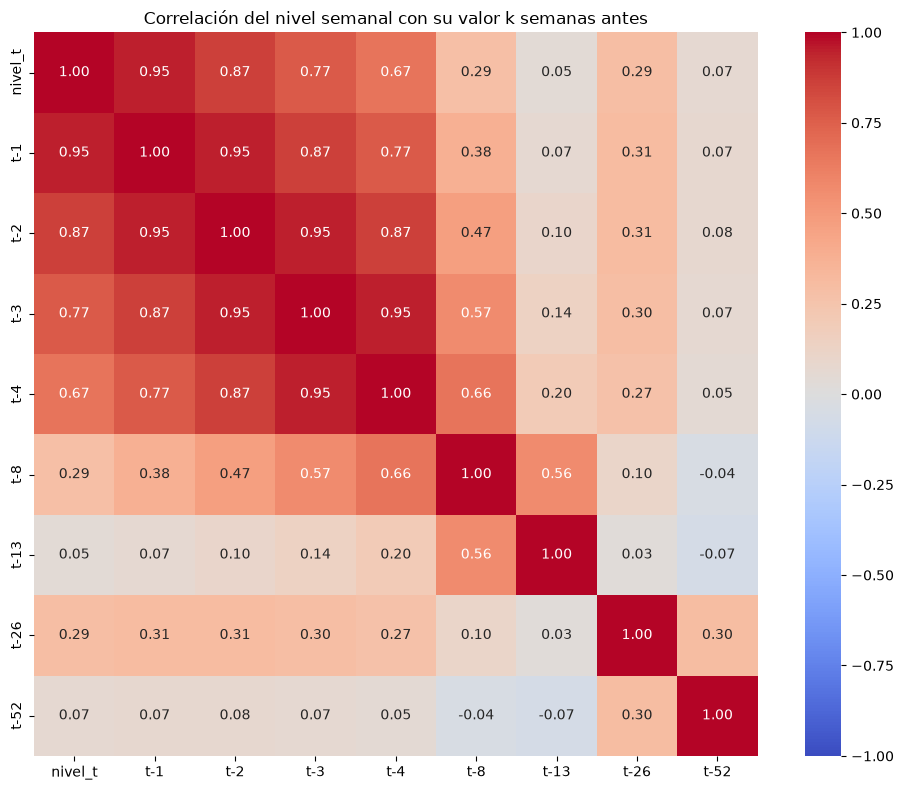

,t-1,t-2,t-3,t-4,t-8,t-13,t-26,t-52
correlacion,0.952,0.867,0.767,0.669,0.287,0.046,0.291,0.068
pares_usados,838.000,825.000,814.000,805.000,770.000,748.000,744.000,663.000


In [24]:
rezagos = [1, 2, 3, 4, 8, 13, 26, 52]

# Cada columna es el nivel de la serie desplazado k semanas hacia atrás
tabla_rezagos = pd.DataFrame({"nivel_t": df_semanal})
for k in rezagos:
    tabla_rezagos[f"t-{k}"] = df_semanal.shift(k)

# Correlación de Pearson entre todas las columnas (ignora las semanas vacías)
correlaciones = tabla_rezagos.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlación del nivel semanal con su valor k semanas antes")
plt.tight_layout()
plt.show()

# Correlación del nivel actual con cada rezago y cuántos pares de semanas se usaron
pares = tabla_rezagos.drop(columns="nivel_t").notna().mul(tabla_rezagos["nivel_t"].notna(), axis=0).sum()
display(pd.DataFrame({"correlacion": correlaciones["nivel_t"].drop("nivel_t"), "pares_usados": pares}).round(3).T)

La primera fila de la matriz muestra la correlación del nivel de una semana con el de semanas anteriores. La relación es muy fuerte con la semana inmediatamente anterior (0.95) y se va debilitando a medida que se mira más atrás: 0.87 con dos semanas, 0.77 con tres y 0.67 con cuatro. Con ocho semanas baja a 0.29 y con trece prácticamente desaparece (0.05). Es decir, el nivel reciente es el que más información da sobre el nivel actual, porque el río cambia de forma gradual.

La correlación con 26 semanas antes (medio año) vuelve a subir a 0.29, mientras que con 52 semanas (un año) es apenas 0.07. Esto se analiza con más detalle en la autocorrelación.

La matriz también muestra que los rezagos cercanos están muy correlacionados entre sí; por ejemplo, el nivel de una semana atrás y el de dos semanas atrás tienen una correlación de 0.95. Esto significa que en buena parte contienen la misma información, lo que se debe tener en cuenta al elegir cuántas semanas anteriores usar en los modelos, especialmente en la regresión lineal, que se ve afectada cuando sus variables están muy relacionadas entre sí.

Las correlaciones se calcularon con entre 663 y 838 pares de semanas, según el rezago, porque solo se usan los pares en los que ambas semanas tienen datos.

Para ver el comportamiento completo, se calcula la correlación del nivel con cada una de las 104 semanas anteriores (dos años), lo que se conoce como autocorrelación. También se grafica el nivel de cada semana contra el de la semana anterior y contra el de 26 semanas antes, para ver la relación directamente.

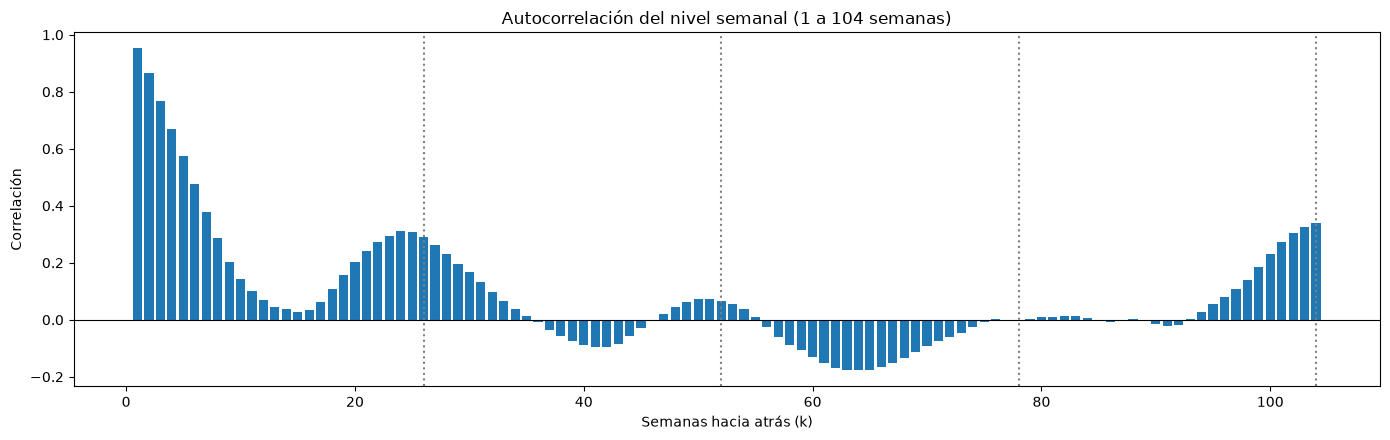

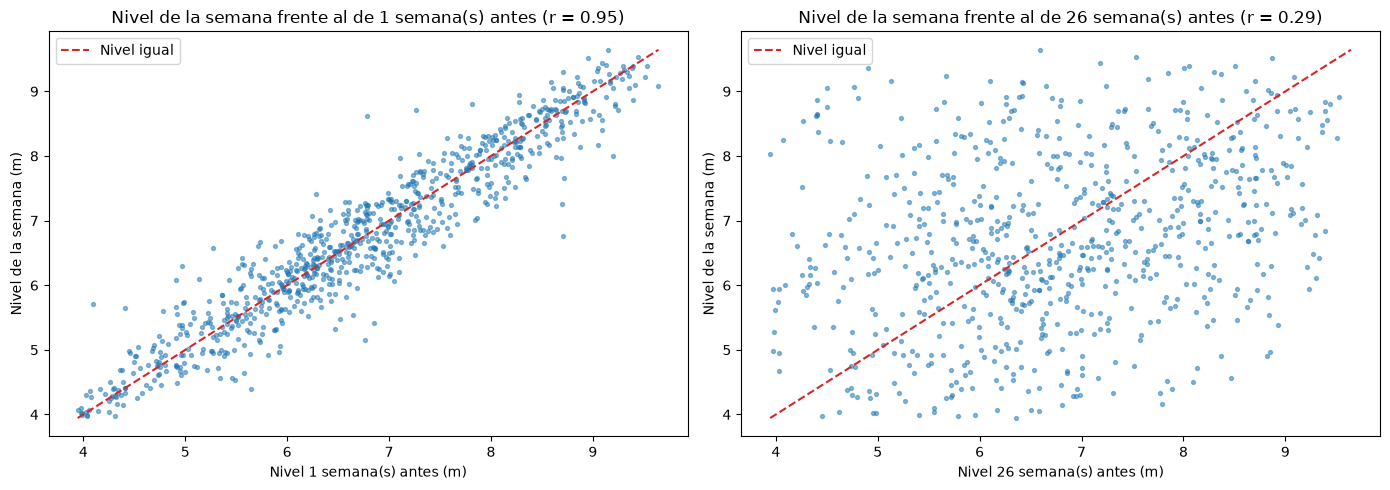

In [25]:
# Autocorrelación: correlación del nivel con su valor k semanas antes, para k de 1 a 104
lags = range(1, 105)
autocorrelacion = [df_semanal.autocorr(k) for k in lags]

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(lags, autocorrelacion, color="#1f77b4", width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
for x in (26, 52, 78, 104):
    ax.axvline(x, color="gray", linestyle=":")
ax.set_title("Autocorrelación del nivel semanal (1 a 104 semanas)")
ax.set_xlabel("Semanas hacia atrás (k)")
ax.set_ylabel("Correlación")
plt.tight_layout()
plt.show()

# Gráficas de dispersión: nivel actual frente al de 1 y 26 semanas antes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
limites = [df_semanal.min(), df_semanal.max()]
for ax, k in zip(axes, [1, 26]):
    ax.scatter(tabla_rezagos[f"t-{k}"], tabla_rezagos["nivel_t"], s=8, alpha=0.5, color="#1f77b4")
    ax.plot(limites, limites, color="#d62728", linestyle="--", label="Nivel igual")
    ax.set_title(f"Nivel de la semana frente al de {k} semana(s) antes (r = {correlaciones.loc['nivel_t', f't-{k}']:.2f})")
    ax.set_xlabel(f"Nivel {k} semana(s) antes (m)")
    ax.set_ylabel("Nivel de la semana (m)")
    ax.legend()
plt.tight_layout()
plt.show()

La autocorrelación confirma lo observado en la matriz. La correlación empieza en 0.95 con una semana y baja de forma continua hasta acercarse a 0 alrededor de las 15 semanas. Luego vuelve a subir y forma un pico de cerca de 0.31 entre las 24 y 26 semanas, es decir, alrededor de medio año. Esto coincide con el diagrama de caja por mes, que mostró dos temporadas de niveles altos al año (mayo a julio y noviembre a diciembre) separadas por unos seis meses: el nivel de una semana tiende a parecerse al de la temporada equivalente medio año antes.

En cambio, la correlación con un año antes (52 semanas) es muy baja (cerca de 0.07), y alrededor de las 40 y 63 semanas se vuelve ligeramente negativa. Esto indica que, aunque el patrón de temporadas se repite, el nivel de un año no se parece mucho al del año anterior, porque hay años más altos y años más bajos, como se vio en la tendencia. Hacia las 104 semanas (dos años) la correlación vuelve a subir a cerca de 0.34, pero con los datos disponibles no es posible afirmar si esto corresponde a un ciclo real de varios años.

Las gráficas de dispersión muestran la diferencia de forma directa. Con una semana de diferencia (r = 0.95) los puntos se ubican muy cerca de la línea roja, que indica un nivel igual al de la semana anterior: el nivel de una semana es casi el mismo que el de la anterior. Con 26 semanas de diferencia (r = 0.29) los puntos están muy dispersos y solo se observa una leve tendencia a seguir la línea.

En conclusión, las semanas más recientes (de una a cuatro semanas atrás) son las que más información aportan para predecir el nivel. La época del año también aporta información, pero de forma más débil y no a través del nivel de un año antes, por lo que es más conveniente representarla con variables que indiquen el mes o la semana del año.

# **2. Diseño de experimentos y recolección de resultados**
# **2.1. Preparación de los datos para los modelos**
En la sección anterior se limpiaron los datos y se construyó la serie semanal. Para entrenar modelos supervisados, esta serie se debe convertir en una tabla con variables de entrada (X) y una variable objetivo (y). En este caso, la variable objetivo es el nivel promedio de una semana, y las variables de entrada se construyen solo con información de semanas anteriores, que es la que estaría disponible al momento de hacer la predicción.

## **2.1.1. Cobertura mínima de las semanas**
En la sección 1.6 se encontró que algunas semanas tienen muy pocas horas con datos válidos (en un caso, una sola hora), por lo que su promedio puede no representar el nivel real de esa semana. Antes de construir las variables se define una cobertura mínima: las semanas por debajo de ella se tratan como semanas sin datos.

In [26]:
print("Semanas que quedarían con datos según la cobertura mínima exigida:")
filas = []
for c in [0, 0.25, 0.5, 0.75, 0.9]:
    acepta = df_semanal.notna() & (cobertura_semanal >= c)
    filas.append({"cobertura_minima_%": int(c * 100), "semanas_con_datos": acepta.sum(),
                  "semanas_descartadas": df_semanal.notna().sum() - acepta.sum()})
display(pd.DataFrame(filas).set_index("cobertura_minima_%").T)

COBERTURA_MINIMA = 0.5
nivel_semanal = df_semanal.where(cobertura_semanal >= COBERTURA_MINIMA)
print(f"Semanas con datos usando una cobertura mínima de {COBERTURA_MINIMA:.0%}: {nivel_semanal.notna().sum()}")

Semanas que quedarían con datos según la cobertura mínima exigida:


cobertura_minima_%,0,25,50,75,90
semanas_con_datos,855,823,798,756,701
semanas_descartadas,0,32,57,99,154


Semanas con datos usando una cobertura mínima de 50%: 798


La tabla muestra cuántas semanas se conservan según la cobertura mínima exigida. Sin ningún mínimo hay 855 semanas con datos; al exigir el 25 % de las horas se descartan 32, con el 50 % se descartan 57, con el 75 % se descartan 99 y con el 90 % se descartan 154. Se eligió una cobertura mínima del 50 %: una semana debe tener al menos 84 horas con datos válidos (tres días y medio), es decir, el promedio se calcula con la mayor parte de la semana. Exigir más cobertura descartaría cada vez más semanas (42 más al pasar al 75 % y 97 más al pasar al 90 %), lo que reduciría los datos disponibles para entrenar. Con este criterio quedan 798 semanas con datos.

## **2.1.2. Creación de variables**
Las variables de entrada se construyen a partir de lo encontrado en la inspección:

| Variable | Qué representa | Justificación |
|---|---|---|
| nivel_t-1 a nivel_t-4 | Nivel de 1, 2, 3 y 4 semanas antes (rezagos) | Son las semanas con mayor correlación con el nivel actual (de 0.95 a 0.67) |
| media_4sem | Promedio de las 4 semanas anteriores | Resume el nivel reciente en un solo valor y suaviza variaciones de una semana |
| desv_4sem | Desviación estándar de las 4 semanas anteriores | Indica si el río ha estado estable o cambiando en el último mes |
| cambio_1sem | Diferencia entre el nivel de 1 y 2 semanas antes | Indica si el río venía subiendo o bajando la última semana |
| cambio_4sem | Diferencia entre el nivel de 1 y 4 semanas antes | Indica la tendencia del último mes |
| dia_sin, dia_cos | Época del año, transformada con seno y coseno | La inspección mostró dos temporadas altas y dos bajas al año; el nivel de un año antes casi no está correlacionado (0.07), así que la época del año se representa directamente |
| semestre_sin, semestre_cos | Ciclo de medio año, transformado con seno y coseno | El diagrama de caja por mes mostró dos temporadas altas al año y la autocorrelación tuvo un pico en 26 semanas; el ciclo anual (dia_sin, dia_cos) tiene un solo máximo por año y no puede representar ese patrón |

Todas las variables se calculan con semanas anteriores a la que se quiere predecir; nunca se usa el nivel de la propia semana como entrada, porque en una predicción real ese valor todavía no se conoce.

Para la época del año se usa el día del año en que termina cada semana. Este valor es cíclico: el 31 de diciembre (día 365) está justo antes del 1 de enero (día 1), pero si se usara como número, el modelo los vería como los valores más alejados. Al transformarlo con seno y coseno, ambos días quedan cerca, y cada época del año queda representada por una combinación única de los dos valores. Se usa el día del año y no el número de semana porque algunos años tienen 53 semanas y otros 52.

Como la serie semanal tiene un registro por semana, incluidas las semanas vacías, las semanas vacías hacen que las variables que dependen de ellas también queden vacías. Las filas con algún valor vacío se eliminan, ya que no se pueden usar para entrenar. Así no se rellena con valores inventados ninguno de los huecos largos de la serie.

In [27]:
datos = pd.DataFrame({"nivel": nivel_semanal})

# Rezagos: nivel de 1 a 4 semanas antes
for k in [1, 2, 3, 4]:
    datos[f"nivel_t-{k}"] = nivel_semanal.shift(k)

# Ventana móvil sobre las 4 semanas anteriores (shift(1) para no usar la semana actual)
pasado = nivel_semanal.shift(1)
datos["media_4sem"] = pasado.rolling(4).mean()
datos["desv_4sem"] = pasado.rolling(4).std()

# Cambio y tendencia
datos["cambio_1sem"] = nivel_semanal.shift(1) - nivel_semanal.shift(2)
datos["cambio_4sem"] = nivel_semanal.shift(1) - nivel_semanal.shift(4)

# Época del año con seno y coseno
dia = datos.index.day_of_year
datos["dia_sin"] = np.sin(2 * np.pi * dia / 365.25)
datos["dia_cos"] = np.cos(2 * np.pi * dia / 365.25)

datos["semestre_sin"] = np.sin(2 * np.pi * dia / (365.25 / 2))
datos["semestre_cos"] = np.cos(2 * np.pi * dia / (365.25 / 2))

print(f"Semanas en la serie: {len(datos)}")
datos = datos.dropna()
print(f"Filas completas para entrenar y probar: {len(datos)}")
display(datos.head())

Semanas en la serie: 1139
Filas completas para entrenar y probar: 697


,nivel,nivel_t-1,nivel_t-2,nivel_t-3,nivel_t-4,media_4sem,desv_4sem,cambio_1sem,cambio_4sem,dia_sin,dia_cos,semestre_sin,semestre_cos
FechaObservacion,,,,,,,,,,,,,
2005-02-06,8.553333,9.091845,9.411786,9.124583,8.856131,9.121086,0.227724,-0.319940,0.235714,0.594376,0.804187,0.955979,0.293434
2005-02-13,8.201768,8.553333,9.091845,9.411786,9.124583,9.045387,0.358141,-0.538512,-0.571250,0.686676,0.726964,0.998377,0.056952
2005-02-20,7.965060,8.201768,8.553333,9.091845,9.411786,8.814683,0.540777,-0.351565,-1.210017,0.769031,0.639212,0.983147,-0.182817
2005-02-27,7.259416,7.965060,8.201768,8.553333,9.091845,8.453002,0.489691,-0.236709,-1.126786,0.840248,0.542202,0.911169,-0.412034
2005-03-06,7.067256,7.259416,7.965060,8.201768,8.553333,7.994894,0.546647,-0.705643,-1.293917,0.899296,0.437340,0.786597,-0.617467


De las 1139 semanas de la serie, 798 tienen datos válidos, pero solo 697 quedan como filas completas para entrenar y probar. Las 101 semanas restantes se pierden porque cada fila necesita las 4 semanas anteriores para calcular los rezagos, la ventana móvil y los cambios. Al inicio de la serie y después de cada interrupción, las primeras 4 semanas con datos no tienen suficiente historia y quedan con valores vacíos. Esto evita construir variables a partir de semanas que no existen o que se separaron por un periodo sin datos.

## **2.1.3. División en entrenamiento y prueba**

Los modelos aprenden a partir de ejemplos en los que ya se conoce la respuesta: durante el entrenamiento ajustan sus parámetros (por ejemplo, los coeficientes de una regresión) para que sus predicciones se parezcan lo más posible a los valores reales. Si se evaluaran con los mismos ejemplos con los que aprendieron, un modelo podría obtener un error muy bajo solo por memorizarlos, sin haber aprendido el comportamiento del río (sobreajuste). Por eso se reserva un conjunto de prueba que los modelos no ven durante el entrenamiento y que se usa una sola vez al final, para medir qué tan bien predicen semanas nuevas.

En una serie de tiempo no se pueden separar las filas al azar, porque el modelo entrenaría con semanas posteriores a las que luego debe predecir, y los resultados serían mejores de lo que serían en la realidad. Por eso la división es cronológica: el 80 % más antiguo de las filas se usa para entrenar y el 20 % más reciente para la prueba final. Así, la evaluación simula el uso real del modelo: aprender del pasado y predecir semanas que nunca ha visto.

Entrenamiento: 557 semanas, de 2005-02-06 a 2023-08-06
Prueba: 140 semanas, de 2023-08-13 a 2026-10-18


,count,mean,std,min,25%,50%,75%,max
Entrenamiento,557.0,6.91,1.24,4.33,5.99,6.78,7.91,9.53
Prueba,140.0,6.23,1.22,3.97,5.53,6.25,7.06,8.57


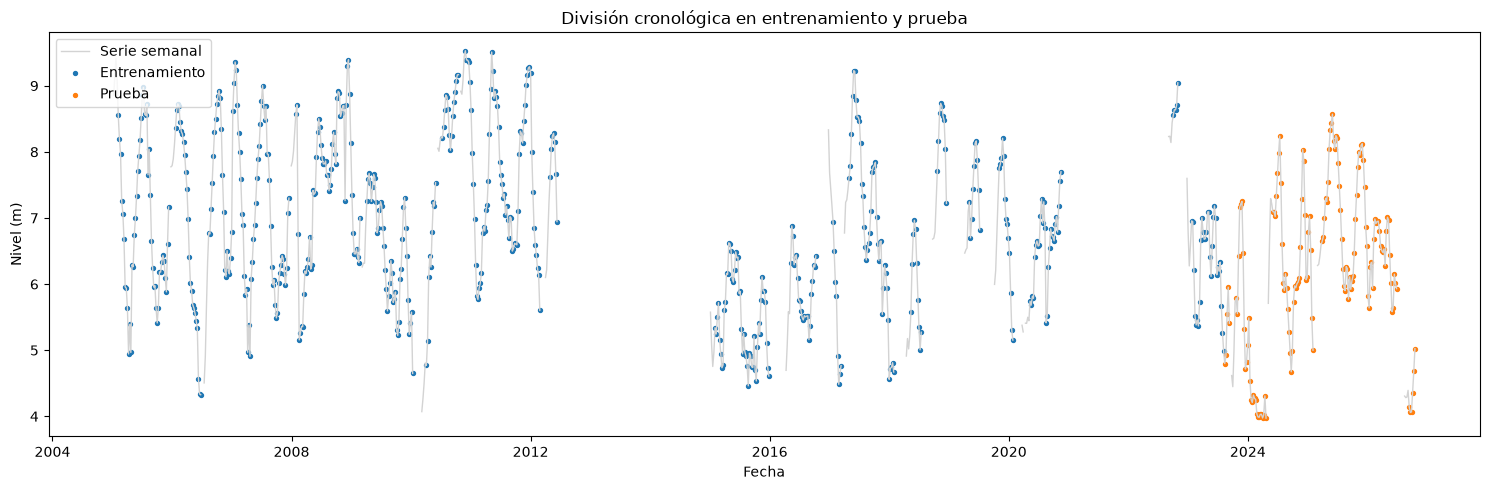

In [28]:
corte = int(len(datos) * 0.8)
entrenamiento = datos.iloc[:corte]
prueba = datos.iloc[corte:]

X_train, y_train = entrenamiento.drop(columns="nivel"), entrenamiento["nivel"]
X_test, y_test = prueba.drop(columns="nivel"), prueba["nivel"]

print(f"Entrenamiento: {len(entrenamiento)} semanas, de {entrenamiento.index.min().date()} a {entrenamiento.index.max().date()}")
print(f"Prueba: {len(prueba)} semanas, de {prueba.index.min().date()} a {prueba.index.max().date()}")
display(pd.DataFrame({"Entrenamiento": y_train.describe(), "Prueba": y_test.describe()}).round(2).T)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(nivel_semanal.index, nivel_semanal.values, color="lightgray", linewidth=1, label="Serie semanal")
ax.scatter(y_train.index, y_train, s=8, color="#1f77b4", label="Entrenamiento")
ax.scatter(y_test.index, y_test, s=8, color="#ff7f0e", label="Prueba")
ax.set_title("División cronológica en entrenamiento y prueba")
ax.set_xlabel("Fecha")
ax.set_ylabel("Nivel (m)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

El conjunto de entrenamiento tiene 557 semanas, del 6 de febrero de 2005 al 6 de agosto de 2023, y el de prueba tiene 140 semanas, del 13 de agosto de 2023 al 18 de octubre de 2026. La prueba abarca más de tres años, por lo que incluye varias temporadas altas y bajas, y permite evaluar los modelos en condiciones variadas.

Los dos conjuntos no tienen exactamente la misma distribución. El nivel promedio es menor en la prueba (6.23 m) que en el entrenamiento (6.91 m), y la prueba contiene niveles más bajos que cualquiera visto durante el entrenamiento: el mínimo de la prueba es 3.97 m, mientras que el del entrenamiento es 4.33 m. Esto corresponde a la temporada seca de 2024, la más baja de toda la serie. Es una situación realista, porque en la práctica un modelo debe predecir condiciones que no necesariamente ocurrieron antes. Sin embargo, es importante para analizar los resultados: los árboles de decisión y el random forest no pueden predecir valores fuera del rango que vieron en el entrenamiento, por lo que se espera que tengan más error en esas semanas que modelos como la regresión lineal o las redes neuronales.

## **2.1.4. Selección de características**
Se usa un método de filtro: se calcula la correlación de cada variable con el nivel y entre las variables, usando solo los datos de entrenamiento para que la prueba no influya en ninguna decisión.

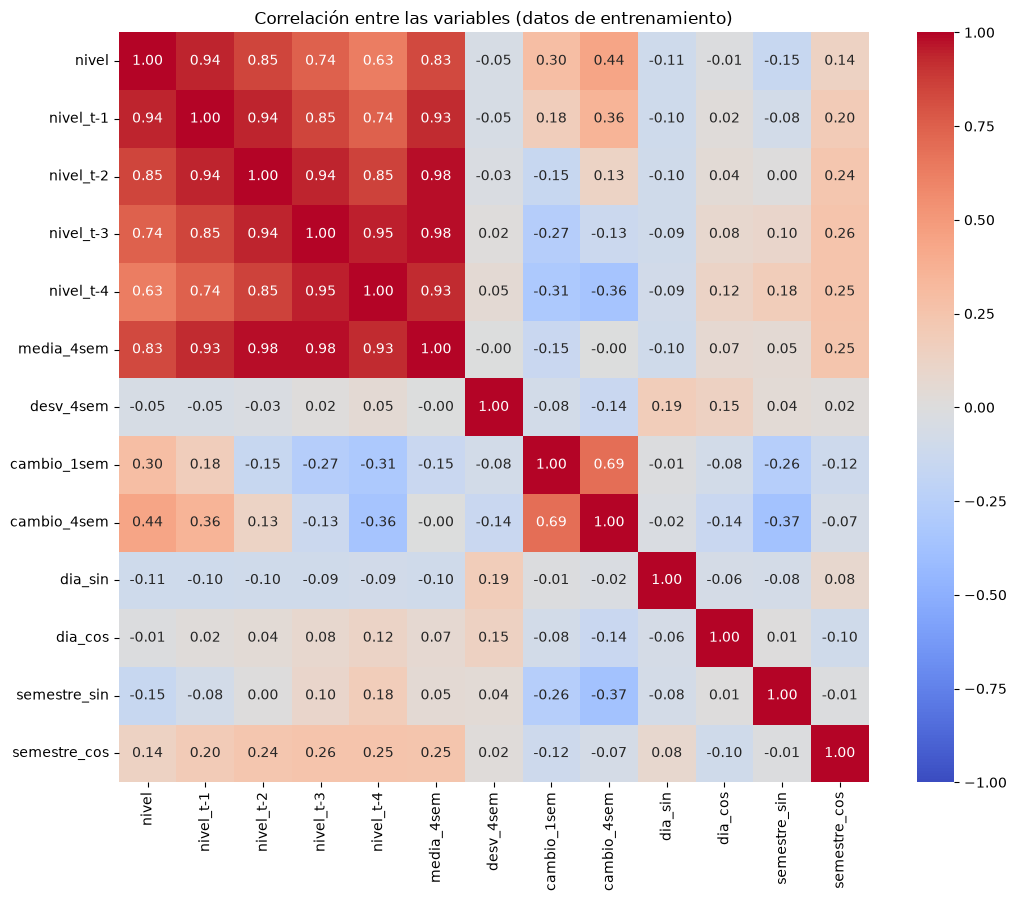

,nivel_t-1,nivel_t-2,media_4sem,nivel_t-3,nivel_t-4,cambio_4sem,cambio_1sem,semestre_sin,semestre_cos,dia_sin,desv_4sem,dia_cos
correlacion_con_nivel,0.945,0.851,0.83,0.742,0.628,0.443,0.296,-0.155,0.14,-0.105,-0.051,-0.013


In [29]:
correlaciones_train = entrenamiento.corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlaciones_train, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlación entre las variables (datos de entrenamiento)")
plt.tight_layout()
plt.show()

display(correlaciones_train["nivel"].drop("nivel").sort_values(key=abs, ascending=False)
        .round(3).to_frame("correlacion_con_nivel").T)

Las variables con mayor correlación con el nivel son los rezagos: 0.945 con la semana anterior, 0.851 con dos semanas, 0.742 con tres y 0.628 con cuatro. Les siguen el promedio de las 4 semanas anteriores (0.83) y los cambios de 4 semanas (0.443) y de una semana (0.296). Las variables de cambio aportan información distinta a la de los rezagos: indican si el río venía subiendo o bajando, y no solo en qué nivel estaba.

Las variables de época del año tienen correlaciones lineales bajas, pero el ciclo semestral (−0.155 y 0.14) se relaciona más con el nivel que el ciclo anual (−0.105 y −0.013), lo que confirma que el patrón de dos temporadas por año encontrado en la inspección se representa mejor con un ciclo de medio año. Además, el ciclo semestral se relaciona con los cambios del nivel (−0.37 con el cambio de 4 semanas), es decir, la época del año indica si el río suele estar subiendo o bajando. La desviación de las 4 semanas anteriores casi no tiene correlación con el nivel (−0.051). Una correlación lineal baja no significa que una variable no sirva: la correlación de Pearson solo mide relaciones en línea recta, y la época del año influye en el nivel de forma cíclica. Los árboles, el random forest y las redes neuronales pueden aprovechar relaciones no lineales, así que estas variables se conservan.

La matriz también muestra una alta colinealidad entre los rezagos y el promedio de 4 semanas (por ejemplo, 0.98 entre el promedio y los rezagos de 2 y 3 semanas, y entre 0.94 y 0.95 entre rezagos consecutivos). Estas variables contienen en buena parte la misma información. Esto no afecta a los árboles ni al random forest, pero sí a la regresión lineal, cuyos coeficientes se vuelven inestables cuando las variables de entrada están muy relacionadas entre sí. Por eso, en lugar de eliminar variables a mano, en la regresión se usarán versiones con regularización (Ridge y Lasso), que reducen el efecto de la colinealidad y, en el caso de Lasso, pueden llevar a cero los coeficientes de las variables que no aportan. Esta es una forma de selección de características integrada en el entrenamiento (método embedded). Además, el random forest permitirá ver la importancia de cada variable después del entrenamiento.

Por estas razones se conservan las 12 variables para todos los modelos.

## **2.1.5. Escalamiento y otras transformaciones**
- **Escalamiento:** las variables tienen escalas distintas (el nivel está entre 4 y 10 m, mientras que el seno y el coseno están entre -1 y 1). Esto afecta a los modelos que se entrenan con descenso del gradiente, como las redes neuronales (MLP y DNN), y a la regresión Lasso, cuya penalización depende del tamaño de los coeficientes. Se usa `StandardScaler`, que resta la media y divide por la desviación estándar de cada variable, porque la distribución del nivel es simétrica y no tiene valores extremos erróneos después de la limpieza. El escalador se ajusta únicamente con los datos de entrenamiento y luego se aplica a entrenamiento y prueba, para que la prueba no influya en ninguna decisión. Los árboles de decisión y el random forest usan las variables sin escalar, porque dividen los datos por umbrales y no por distancias.
- **Transformación logarítmica:** no se aplica, porque la distribución del nivel es simétrica (asimetría de 0.04).
- **Variables categóricas:** no hay; todas las variables son numéricas, por lo que no se usa codificación (one-hot ni integer encoding).
- **Balanceo de clases:** no aplica, porque es un problema de regresión y no hay clases.
- **Vectorización:** no aplica, porque los datos no son texto ni imágenes.
- **Reducción de dimensionalidad (PCA):** no se aplica, porque hay solo 12 variables y cada una tiene un significado claro. Con tan pocas variables no se presenta la maldición de la dimensionalidad, y PCA haría más difícil interpretar los modelos.

In [30]:
# El escalador se ajusta solo con entrenamiento y se aplica a entrenamiento y prueba
scaler = StandardScaler()
X_train_esc = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_esc = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Medias en entrenamiento después de escalar (deberían ser ~0):")
print(X_train_esc.mean().round(3).to_string())
print("\nDesviaciones en entrenamiento después de escalar (deberían ser ~1):")
print(X_train_esc.std().round(3).to_string())

Medias en entrenamiento después de escalar (deberían ser ~0):
nivel_t-1      -0.0
nivel_t-2      -0.0
nivel_t-3       0.0
nivel_t-4      -0.0
media_4sem     -0.0
desv_4sem      -0.0
cambio_1sem     0.0
cambio_4sem    -0.0
dia_sin         0.0
dia_cos        -0.0
semestre_sin   -0.0
semestre_cos    0.0

Desviaciones en entrenamiento después de escalar (deberían ser ~1):
nivel_t-1       1.001
nivel_t-2       1.001
nivel_t-3       1.001
nivel_t-4       1.001
media_4sem      1.001
desv_4sem       1.001
cambio_1sem     1.001
cambio_4sem     1.001
dia_sin         1.001
dia_cos         1.001
semestre_sin    1.001
semestre_cos    1.001


Después de escalar, todas las variables de entrenamiento tienen media 0 y desviación estándar cercana a 1. La desviación aparece como 1.001 y no como 1 exacto porque pandas calcula la desviación estándar dividiendo entre n − 1, mientras que `StandardScaler` divide entre n; con 557 semanas de entrenamiento, esa diferencia es de 0.1 %. El conjunto de prueba no tiene exactamente media 0 ni desviación 1, porque se transformó con la media y la desviación del entrenamiento, que es lo correcto para que la prueba no influya en el escalamiento.

## **2.2. Configuración de los experimentos**
Todos los modelos se entrenan y evalúan con la misma configuración, para que sus resultados se puedan comparar. Para cada modelo se sigue la misma secuencia: primero se entrena un modelo base con los hiperparámetros por defecto, se compara su desempeño en entrenamiento y prueba para identificar sobreajuste o subajuste, y luego se ajustan los hiperparámetros con `GridSearchCV`.

Además de los parámetros que aprenden durante el entrenamiento, los modelos tienen hiperparámetros que se deben fijar antes de entrenar, como la intensidad de la regularización en Lasso o la profundidad máxima de un árbol. No existe una forma de conocer de antemano sus mejores valores: si un árbol es muy profundo puede memorizar los datos, y si es muy pequeño puede no aprender lo suficiente. `GridSearchCV` prueba de forma automática todas las combinaciones de una rejilla de valores y elige la que tiene menor error. Ese error no se puede medir con el conjunto de prueba, porque si se eligieran los hiperparámetros según sus resultados, la prueba dejaría de ser una evaluación independiente. Por eso se mide con validación cruzada: el conjunto de entrenamiento se divide en varias particiones, en cada una el modelo se entrena con una parte y se evalúa con otra, y se promedia el error de todas. Usar varias particiones en lugar de una sola hace que la elección no dependa de un único periodo, que podría ser especialmente fácil o difícil de predecir.

- **Validación cruzada temporal:** `GridSearchCV` usa `TimeSeriesSplit` con 5 particiones. A diferencia de la validación cruzada K-folds, `TimeSeriesSplit` divide el entrenamiento en bloques consecutivos y siempre valida con semanas posteriores a las usadas para entrenar. Así, en cada partición el modelo aprende del pasado y se evalúa en el futuro, igual que en la división entre entrenamiento y prueba. El conjunto de prueba no se usa en ningún momento para elegir hiperparámetros.
- **Métrica para elegir hiperparámetros:** la raíz del error cuadrático medio (RMSE), que se expresa en metros, las mismas unidades del nivel del río. Además, al elevar los errores al cuadrado, el RMSE penaliza más los errores grandes, que en este problema son los más importantes, porque un error grande durante una creciente es el que más consecuencias tendría. Scikit-learn la maneja en negativo (`neg_root_mean_squared_error`) porque siempre selecciona la combinación con el valor más alto; para mostrarla como un valor positivo se multiplica por −1.
- **Métricas de evaluación:** para cada modelo se calculan el coeficiente de determinación (R²), el error absoluto medio (MAE), el error cuadrático medio (MSE), el RMSE, el error porcentual absoluto medio (MAPE), y el MAE y el RMSE normalizados por el rango de los valores reales (NMAE y NRMSE), tanto en entrenamiento como en prueba.

In [31]:
# Validación cruzada temporal y métrica para elegir hiperparámetros
tscv = TimeSeriesSplit(n_splits=5)
metrica_busqueda = "neg_root_mean_squared_error"

# Particiones que usará GridSearchCV dentro del conjunto de entrenamiento
particiones = []
for i, (idx_entrena, idx_valida) in enumerate(tscv.split(X_train), start=1):
    particiones.append({
        "particion": i,
        "semanas_entrenamiento": len(idx_entrena),
        "entrena_desde": X_train.index[idx_entrena[0]].date(),
        "entrena_hasta": X_train.index[idx_entrena[-1]].date(),
        "semanas_validacion": len(idx_valida),
        "valida_desde": X_train.index[idx_valida[0]].date(),
        "valida_hasta": X_train.index[idx_valida[-1]].date(),
    })
display(pd.DataFrame(particiones).set_index("particion"))

,semanas_entrenamiento,entrena_desde,entrena_hasta,semanas_validacion,valida_desde,valida_hasta
particion,,,,,,
1,97,2005-02-06,2007-02-25,92,2007-03-04,2009-01-04
2,189,2005-02-06,2009-01-04,92,2009-01-11,2011-04-10
3,281,2005-02-06,2011-04-10,92,2011-04-17,2015-10-25
4,373,2005-02-06,2015-10-25,92,2015-11-01,2018-10-28
5,465,2005-02-06,2018-10-28,92,2018-11-04,2023-08-06


La tabla muestra las 5 particiones que usa `GridSearchCV` dentro del conjunto de entrenamiento. En cada una, el entrenamiento empieza en febrero de 2005 y va creciendo (97, 189, 281, 373 y 465 semanas), mientras que la validación siempre tiene 92 semanas y empieza justo después de donde termina el entrenamiento. Así, ninguna partición usa semanas posteriores para predecir semanas anteriores.

Cada bloque de validación tiene 92 semanas con datos, casi dos años, por lo que incluye tanto temporadas de niveles altos como de niveles bajos. Las particiones 3 y 5 abarcan un periodo de tiempo más largo porque incluyen los periodos sin datos de 2012 a 2014 y de 2021 a 2022, pero mantienen el mismo número de semanas con datos. La primera partición entrena con solo 97 semanas, por lo que es esperable que en ella los modelos tengan un error mayor; `GridSearchCV` elige los hiperparámetros con el promedio de las 5 particiones.

In [36]:
def evaluar_modelo(valores_reales, predicciones):
    mae = mean_absolute_error(valores_reales, predicciones)
    mse = mean_squared_error(valores_reales, predicciones)
    rmse = np.sqrt(mse)
    rango = np.max(valores_reales) - np.min(valores_reales)
    return {"R2": r2_score(valores_reales, predicciones), "MAE": mae, "MSE": mse, "RMSE": rmse,
            "MAPE": mean_absolute_percentage_error(valores_reales, predicciones),
            "NMAE": mae / rango if rango > 0 else np.nan,
            "NRMSE": rmse / rango if rango > 0 else np.nan}


def graficar_predicciones(nombre_modelo, predicciones_prueba):
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(nivel_semanal.index, nivel_semanal.values, color="lightgray", linewidth=1, label="Serie semanal")
    ax.plot(y_test.index, y_test.values, color="#1f77b4", linewidth=1.5, label="Prueba: valor real")
    ax.plot(y_test.index, predicciones_prueba, color="#ff7f0e", linewidth=1.5, linestyle="--",
            label="Prueba: valor predicho")
    ax.set_xlim(y_test.index.min() - pd.Timedelta(weeks=26), y_test.index.max() + pd.Timedelta(weeks=2))
    ax.set_title(f"Nivel real y predicho en el conjunto de prueba - {nombre_modelo}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Nivel (m)")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()



def graficar_real_vs_predicho(nombre_modelo, predicciones_prueba, predicciones_referencia=None):
    fig, ax = plt.subplots(figsize=(6, 6))
    if predicciones_referencia is not None:
        ax.scatter(y_test, predicciones_referencia, s=15, alpha=0.4, color="gray", label="Predicción ingenua")
    ax.scatter(y_test, predicciones_prueba, s=15, alpha=0.8, color="#ff7f0e", label=nombre_modelo)
    limites = [min(y_test.min(), np.min(predicciones_prueba)), max(y_test.max(), np.max(predicciones_prueba))]
    ax.plot(limites, limites, "k--", label="Predicción perfecta")
    ax.set_title(f"Nivel real frente a predicho (prueba) - {nombre_modelo}")
    ax.set_xlabel("Nivel real (m)")
    ax.set_ylabel("Nivel predicho (m)")
    ax.legend()
    plt.tight_layout()
    plt.show()

## **2.3. Referencia: predicción ingenua**
Antes de entrenar los modelos se calcula una predicción de referencia, que consiste en suponer que el nivel de cada semana es igual al de la semana anterior. Esta predicción no requiere entrenamiento: se toma directamente la variable `nivel_t-1`. Como en la inspección se encontró que el nivel de una semana tiene una correlación de 0.95 con el de la semana anterior, esta referencia puede tener un error bajo. Sirve para interpretar los resultados de los modelos: un modelo solo aporta valor si se equivoca menos que esta predicción.

In [33]:
# Predicción ingenua: el nivel de la semana es igual al de la semana anterior
pred_ingenua_train = X_train["nivel_t-1"]
pred_ingenua = X_test["nivel_t-1"]

metricas_ingenua_train = evaluar_modelo(y_train, pred_ingenua_train)
metricas_ingenua = evaluar_modelo(y_test, pred_ingenua)

display(pd.DataFrame({"Entrenamiento": metricas_ingenua_train, "Prueba": metricas_ingenua}).round(3))

,Entrenamiento,Prueba
R2,0.890,0.895
MAE,0.308,0.301
MSE,0.167,0.155
RMSE,0.409,0.394
MAPE,0.046,0.049
NMAE,0.059,0.065
NRMSE,0.079,0.086


La predicción ingenua tiene un error absoluto medio de 0.301 m en prueba, es decir, suponer que el río estará igual que la semana anterior lleva a equivocarse en promedio unos 30 cm. Su R² es de 0.895, por lo que esta predicción ya explica cerca del 90 % de la variación del nivel. Los resultados en entrenamiento y prueba son muy parecidos, lo que confirma que el río cambia poco de una semana a otra en todo el periodo. Esta es una referencia exigente: para justificar su complejidad, los modelos deben equivocarse menos que 0.301 m de MAE y 0.394 m de RMSE en prueba.

## **2.4. Regresión lineal multivariada**
La regresión lineal estima un coeficiente para cada variable de entrada, de manera que la suma de los errores al cuadrado en el entrenamiento sea la menor posible. El nivel predicho es el intercepto más la suma de cada variable multiplicada por su coeficiente. No tiene hiperparámetros que ajustar, por lo que no se usa `GridSearchCV`. Es el modelo más simple de los evaluados y sirve como punto de partida para comparar los demás.

Se usan las variables escaladas. Como todas quedaron con media 0 y desviación 1, el tamaño de cada coeficiente indica cuánto cambia el nivel predicho, en metros, cuando esa variable aumenta una desviación estándar, y los coeficientes se pueden comparar entre sí.

In [34]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_esc, y_train)

pred_lineal_train = modelo_lineal.predict(X_train_esc)
pred_lineal = modelo_lineal.predict(X_test_esc)

metricas_lineal_train = evaluar_modelo(y_train, pred_lineal_train)
metricas_lineal = evaluar_modelo(y_test, pred_lineal)

print("Intercepto:", round(modelo_lineal.intercept_, 4))
print("\nCoeficientes:")
display(pd.Series(modelo_lineal.coef_, index=X_train_esc.columns).round(4).to_frame("coeficiente"))

print("Comparación con la predicción ingenua:")
display(pd.DataFrame({
    "Ingenua - Entrenamiento": metricas_ingenua_train,
    "Ingenua - Prueba": metricas_ingenua,
    "Lineal - Entrenamiento": metricas_lineal_train,
    "Lineal - Prueba": metricas_lineal,
}).round(3))

Intercepto: 6.9058

Coeficientes:


,coeficiente
nivel_t-1,0.3839
nivel_t-2,0.3021
nivel_t-3,-0.0037
nivel_t-4,0.2082
media_4sem,0.2336
desv_4sem,0.0209
cambio_1sem,0.2511
cambio_4sem,0.2457
dia_sin,-0.0167
dia_cos,-0.0270


Comparación con la predicción ingenua:


,Ingenua - Entrenamiento,Ingenua - Prueba,Lineal - Entrenamiento,Lineal - Prueba
R2,0.890,0.895,0.914,0.920
MAE,0.308,0.301,0.267,0.263
MSE,0.167,0.155,0.131,0.119
RMSE,0.409,0.394,0.362,0.345
MAPE,0.046,0.049,0.041,0.044
NMAE,0.059,0.065,0.051,0.057
NRMSE,0.079,0.086,0.070,0.075


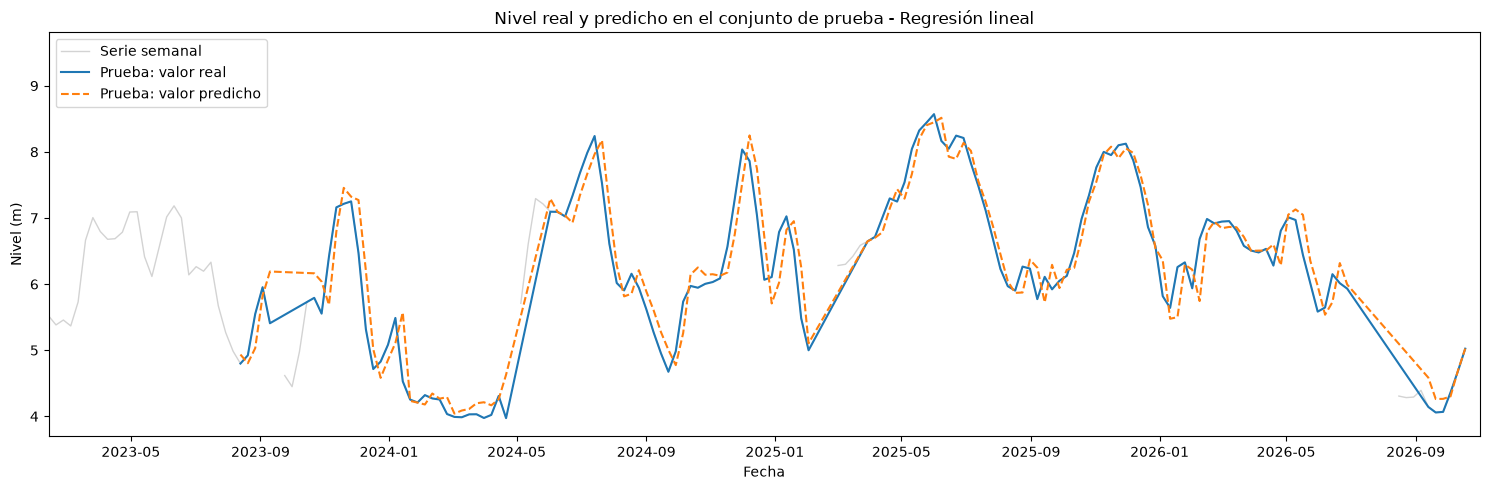

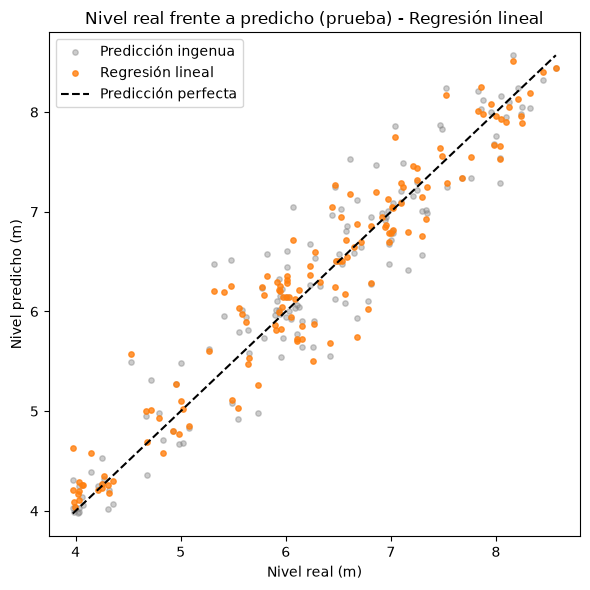

In [37]:
graficar_predicciones("Regresión lineal", pred_lineal)
graficar_real_vs_predicho("Regresión lineal", pred_lineal, pred_ingenua)

La regresión lineal obtuvo en prueba un MAE de 0.263 m, un RMSE de 0.345 m, un R² de 0.920 y un MAPE de 4.4 %. Frente a la predicción ingenua, reduce el MAE en 12.6 % y el RMSE en 12.4 %, es decir, pasa de equivocarse unos 30 cm a unos 26 cm en promedio. Esto indica que las demás variables aportan información, aunque la mayor parte de la predicción proviene del nivel de la semana anterior. Los errores en entrenamiento (RMSE de 0.362 m) y en prueba (0.345 m) son muy parecidos, por lo que no hay señales de sobreajuste.

El intercepto (6.906 m) coincide con el nivel promedio del entrenamiento, porque al escalar todas las variables quedaron con media 0. Los coeficientes, en cambio, no se pueden interpretar de forma individual. Las variables `cambio_1sem`, `cambio_4sem` y `media_4sem` son combinaciones exactas de los rezagos (por ejemplo, `cambio_1sem` es la resta entre `nivel_t-1` y `nivel_t-2`), por lo que existe una multicolinealidad perfecta: hay muchas combinaciones de coeficientes que producen exactamente las mismas predicciones, y el modelo reparte el peso entre ellas. Por eso, por ejemplo, `nivel_t-3` tiene un coeficiente casi nulo (−0.004) aunque está muy correlacionado con el nivel. Las variables de época del año tienen coeficientes pequeños (entre −0.058 y −0.017), lo que indica que, en un modelo lineal, aportan poco.

La gráfica muestra que la predicción sigue de cerca el nivel real, pero con un retraso de aproximadamente una semana: en los picos y en los cambios de dirección, el modelo todavía predice la tendencia anterior y se corrige en la semana siguiente. Esto es esperable en un modelo que depende principalmente del nivel de la semana anterior. Durante la temporada seca de 2024, el modelo predice valores cercanos a los reales, aunque son más bajos que cualquiera visto en el entrenamiento, porque una recta puede extenderse fuera del rango de los datos. Los tramos rectos de la gráfica corresponden a semanas sin datos.

La gráfica de valores reales frente a predichos muestra que los puntos de la regresión lineal se distribuyen alrededor de la diagonal sin desviarse sistemáticamente hacia arriba ni hacia abajo, por lo que el modelo no tiende a sobreestimar ni a subestimar el nivel de forma general. Comparados con la predicción ingenua (en gris), los puntos están algo más cerca de la diagonal y hay menos casos muy alejados. Los errores más grandes, de hasta unos 0.6 a 0.7 m, se presentan en niveles intermedios, entre 5.5 m y 7 m, que corresponden a semanas en las que el río sube o baja rápidamente. En los extremos, el modelo tiende a predecir niveles un poco más altos que los reales cuando el río está cerca de 4 m, y un poco más bajos cuando supera los 8 m. Es decir, suaviza los valores extremos, lo cual es importante porque los niveles altos son los más relevantes para anticipar inundaciones.